In [20]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/validate.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/train.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_140.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1639.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_364.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_265.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_511.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1522.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_43.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_356.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-disea

In [21]:
import os
import torch

print("=" * 80)
print("XAI — ENVIRONMENT CHECK")
print("=" * 80)

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# Final RETFound checkpoint
# ------------------------------------------------------------

CHECKPOINT_PATH = (
    "/kaggle/input/datasets/"
    "rithika2006/retfound-best-model-checkpoint/"
    "best_model.pth"
)

print("\nCheckpoint path:")
print(CHECKPOINT_PATH)

print("\nCheckpoint exists:", os.path.exists(CHECKPOINT_PATH))

if os.path.exists(CHECKPOINT_PATH):
    size_gb = os.path.getsize(CHECKPOINT_PATH) / (1024 ** 3)
    print(f"Checkpoint size  : {size_gb:.2f} GB")

print("\n" + "=" * 80)
print("ENVIRONMENT CHECK COMPLETE")
print("=" * 80)

XAI — ENVIRONMENT CHECK
PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4

Checkpoint path:
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint/best_model.pth

Checkpoint exists: True
Checkpoint size  : 3.39 GB

ENVIRONMENT CHECK COMPLETE


In [22]:
import torch

print("=" * 80)
print("XAI — GPU CHECK")
print("=" * 80)

print("CUDA available :", torch.cuda.is_available())
print("CUDA device count :", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i} :", torch.cuda.get_device_name(i))
else:
    print("\n⚠️ No GPU is currently available.")
    print("Please check Kaggle Notebook → Settings → Accelerator.")
    print("For RETFound XAI, select GPU (preferably T4).")

print("=" * 80)

XAI — GPU CHECK
CUDA available : True
CUDA device count : 2
GPU 0 : Tesla T4
GPU 1 : Tesla T4


In [23]:
import os
import subprocess

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"

print("=" * 80)
print("DOWNLOADING RETFOUND REPOSITORY")
print("=" * 80)

if os.path.exists(RETFOUND_REPO):
    print("RETFound repository already exists.")
else:
    print("Cloning RETFound repository...")
    
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/rmaphoh/RETFound_MAE.git",
            RETFOUND_REPO
        ],
        check=True
    )

print("\nRepository exists:", os.path.exists(RETFOUND_REPO))
print(
    "models_vit.py exists:",
    os.path.exists(os.path.join(RETFOUND_REPO, "models_vit.py"))
)

print("\nRepository contents:")
print(os.listdir(RETFOUND_REPO)[:20])

print("=" * 80)
print("RETFOUND REPOSITORY SETUP COMPLETE")
print("=" * 80)

DOWNLOADING RETFOUND REPOSITORY
RETFound repository already exists.

Repository exists: True
models_vit.py exists: True

Repository contents:
['BENCHMARK.md', 'examples', 'main_finetune.py', '.gitignore', 'models_vit.py', 'engine_finetune.py', '.git', 'train.sh', 'util', 'requirements.txt', '__pycache__', 'LICENSE', 'README.md', 'latent_feature.ipynb']
RETFOUND REPOSITORY SETUP COMPLETE


In [24]:
import os
import sys
import importlib.util
import torch
import torch.nn as nn

print("=" * 80)
print("XAI — RETFOUND MODEL RECONSTRUCTION")
print("=" * 80)

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"
MODELS_VIT = os.path.join(RETFOUND_REPO, "models_vit.py")

# ------------------------------------------------------------
# 1. Import RETFound models_vit.py
# ------------------------------------------------------------
sys.path.insert(0, RETFOUND_REPO)

spec = importlib.util.spec_from_file_location(
    "models_vit",
    MODELS_VIT
)

models_vit = importlib.util.module_from_spec(spec)
sys.modules["models_vit"] = models_vit
spec.loader.exec_module(models_vit)

RETFound_mae = models_vit.RETFound_mae

print("✓ RETFound_mae imported successfully")


# ------------------------------------------------------------
# 2. Exact classifier wrapper used during training
# ------------------------------------------------------------
class RETFoundClassifier(nn.Module):

    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):

        features = self.backbone.forward_features(x)

        if features.ndim == 3 and features.shape[1] == 1:
            features = features[:, 0, :]

        logits = self.backbone.head(features)

        return logits


# ------------------------------------------------------------
# 3. Recreate EXACT architecture
# ------------------------------------------------------------
backbone = RETFound_mae(
    img_size=224,
    num_classes=10,
    global_pool=True
)

model = RETFoundClassifier(backbone)


# ------------------------------------------------------------
# 4. Verify architecture
# ------------------------------------------------------------
total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("✓ Model created successfully")

print("\nTotal parameters:")
print(f"{total_params:,}")

print("\nClassification head:")
print(model.backbone.head)

print("\nFC normalization:")
print(model.backbone.fc_norm)

print("=" * 80)
print("MODEL RECONSTRUCTION COMPLETE")
print("=" * 80)

XAI — RETFOUND MODEL RECONSTRUCTION
✓ RETFound_mae imported successfully
✓ Model created successfully

Total parameters:
303,311,882

Classification head:
Linear(in_features=1024, out_features=10, bias=True)

FC normalization:
LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
MODEL RECONSTRUCTION COMPLETE


In [25]:
print("=" * 80)
print("CHECKING RETFOUND MODEL")
print("=" * 80)

print("RETFound_mae available :", RETFound_mae is not None)
print("RETFoundClassifier available :", RETFoundClassifier is not None)

print("\nCreating model...")

backbone = RETFound_mae(
    img_size=224,
    num_classes=10,
    global_pool=True
)

model = RETFoundClassifier(backbone)

total_params = sum(p.numel() for p in model.parameters())

print("✓ Model created successfully")
print("Total parameters:", f"{total_params:,}")
print("Classification head:", model.backbone.head)
print("FC norm:", model.backbone.fc_norm)

print("=" * 80)
print("MODEL CHECK COMPLETE")
print("=" * 80)

CHECKING RETFOUND MODEL
RETFound_mae available : True
RETFoundClassifier available : True

Creating model...
✓ Model created successfully
Total parameters: 303,311,882
Classification head: Linear(in_features=1024, out_features=10, bias=True)
FC norm: LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
MODEL CHECK COMPLETE


In [26]:
print("=" * 80)
print("XAI — MOVING RETFOUND TO GPU")
print("=" * 80)

# ------------------------------------------------------------
# Select GPU
# ------------------------------------------------------------
DEVICE = torch.device("cuda")

print("Using device:", DEVICE)

# ------------------------------------------------------------
# Move model to GPU
# ------------------------------------------------------------
model = model.to(DEVICE)

# ------------------------------------------------------------
# Evaluation mode
# ------------------------------------------------------------
model.eval()

print("✓ Model moved to GPU")
print("✓ Model set to evaluation mode")

# ------------------------------------------------------------
# Verify one parameter
# ------------------------------------------------------------
first_param = next(model.parameters())

print("\nFirst parameter device:", first_param.device)
print("First parameter dtype  :", first_param.dtype)

print("=" * 80)
print("GPU MODEL SETUP COMPLETE")
print("=" * 80)

XAI — MOVING RETFOUND TO GPU
Using device: cuda
✓ Model moved to GPU
✓ Model set to evaluation mode

First parameter device: cuda:0
First parameter dtype  : torch.float32
GPU MODEL SETUP COMPLETE


In [27]:
import os

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "krishba/retfound-rfmid-10-diseases"
)

print("=" * 80)
print("XAI — DATASET STRUCTURE CHECK")
print("=" * 80)

print("Dataset root:")
print(DATASET_ROOT)

print("\nRoot exists:", os.path.exists(DATASET_ROOT))

if os.path.exists(DATASET_ROOT):

    print("\nItems inside dataset root:")
    for item in os.listdir(DATASET_ROOT):
        full_path = os.path.join(DATASET_ROOT, item)

        if os.path.isdir(full_path):
            print(f"[DIR ] {item}")
        else:
            size_mb = os.path.getsize(full_path) / (1024 ** 2)
            print(f"[FILE] {item} ({size_mb:.2f} MB)")

    print("\n" + "-" * 80)
    print("Searching first-level subdirectories...")
    print("-" * 80)

    for item in os.listdir(DATASET_ROOT):

        full_path = os.path.join(DATASET_ROOT, item)

        if os.path.isdir(full_path):

            print(f"\n[{item}]")

            try:
                children = os.listdir(full_path)

                for child in children[:20]:
                    child_path = os.path.join(full_path, child)

                    if os.path.isdir(child_path):
                        print(f"  [DIR ] {child}")
                    else:
                        print(f"  [FILE] {child}")

                if len(children) > 20:
                    print(f"  ... and {len(children) - 20} more")

            except Exception as e:
                print("  Could not read:", e)

print("\n" + "=" * 80)
print("DATASET STRUCTURE CHECK COMPLETE")
print("=" * 80)

XAI — DATASET STRUCTURE CHECK
Dataset root:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases

Root exists: True

Items inside dataset root:
[DIR ] splits_Excel
[DIR ] Validate
[DIR ] Test
[DIR ] Train

--------------------------------------------------------------------------------
Searching first-level subdirectories...
--------------------------------------------------------------------------------

[splits_Excel]
  [FILE] test.xlsx
  [FILE] validate.xlsx
  [FILE] train.xlsx

[Validate]
  [DIR ] DR
  [DIR ] TSLN
  [DIR ] ODP
  [DIR ] Normal
  [DIR ] ARMD
  [DIR ] MH
  [DIR ] BRVO
  [DIR ] DN
  [DIR ] ODC
  [DIR ] MYA

[Test]
  [DIR ] DR
  [DIR ] TSLN
  [DIR ] ODP
  [DIR ] Normal
  [DIR ] ARMD
  [DIR ] MH
  [DIR ] BRVO
  [DIR ] DN
  [DIR ] ODC
  [DIR ] MYA

[Train]
  [DIR ] DR
  [DIR ] TSLN
  [DIR ] ODP
  [DIR ] Normal
  [DIR ] ARMD
  [DIR ] MH
  [DIR ] BRVO
  [DIR ] DN
  [DIR ] ODC
  [DIR ] MYA

DATASET STRUCTURE CHECK COMPLETE


In [28]:
import os

print("=" * 80)
print("KAGGLE INPUT DATASETS")
print("=" * 80)

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 2:
        print(root)

print("=" * 80)

KAGGLE INPUT DATASETS
/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/krishba
/kaggle/input/datasets/rithika2006


In [29]:
import os

BASE = "/kaggle/input/datasets/rithika2006"

print("=" * 80)
print("CHECKING RITHIKA2006 DATASETS")
print("=" * 80)

print("Base exists:", os.path.exists(BASE))

if os.path.exists(BASE):
    print("\nContents:\n")

    for item in os.listdir(BASE):
        path = os.path.join(BASE, item)

        if os.path.isdir(path):
            print(f"[DIR ] {item}")

            # Show immediate contents
            try:
                children = os.listdir(path)

                for child in children[:15]:
                    child_path = os.path.join(path, child)

                    if os.path.isdir(child_path):
                        print(f"       [DIR ] {child}")
                    else:
                        print(f"       [FILE] {child}")

                if len(children) > 15:
                    print(f"       ... {len(children) - 15} more")

            except Exception as e:
                print("       Could not read:", e)

        else:
            print(f"[FILE] {item}")

print("\n" + "=" * 80)
print("CHECK COMPLETE")
print("=" * 80)

CHECKING RITHIKA2006 DATASETS
Base exists: True

Contents:

[DIR ] retfound-best-model-checkpoint
       [FILE] best_model.pth

CHECK COMPLETE


In [30]:
import os

print("=" * 80)
print("KAGGLE INPUT DATASETS")
print("=" * 80)

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    level = root.replace("/kaggle/input/datasets", "").count(os.sep)

    if level <= 3:
        print(root)

print("=" * 80)

KAGGLE INPUT DATASETS
/kaggle/input/datasets
/kaggle/input/datasets/krishba
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train
/kaggle/input/datasets/rithika2006
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint


In [31]:
import os

print("=" * 80)
print("CHECKING ALL KAGGLE INPUTS")
print("=" * 80)

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    level = root.replace("/kaggle/input/datasets", "").count(os.sep)

    if level <= 2:
        print(root)

print("=" * 80)

CHECKING ALL KAGGLE INPUTS
/kaggle/input/datasets
/kaggle/input/datasets/krishba
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases
/kaggle/input/datasets/rithika2006
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint


In [32]:
import os

print("Datasets currently mounted:\n")

for item in os.listdir("/kaggle/input/datasets/rithika2006"):
    print(item)

Datasets currently mounted:

retfound-best-model-checkpoint


In [33]:
import os

print(os.listdir("/kaggle/input/datasets/rithika2006"))

['retfound-best-model-checkpoint']


In [34]:
import os

print(os.listdir("/kaggle/input/datasets"))
print("\nUnder rithika2006:")
print(os.listdir("/kaggle/input/datasets/rithika2006"))

['krishba', 'rithika2006']

Under rithika2006:
['retfound-best-model-checkpoint']


In [35]:
import os

RFMiD_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

print("=" * 80)
print("XAI — RFMiD DATASET VERIFICATION")
print("=" * 80)

print("RFMiD root:")
print(RFMiD_ROOT)

print("\nRoot exists:", os.path.exists(RFMiD_ROOT))

if os.path.exists(RFMiD_ROOT):

    print("\nContents:")

    for item in os.listdir(RFMiD_ROOT):
        path = os.path.join(RFMiD_ROOT, item)

        if os.path.isdir(path):
            print(f"[DIR ] {item}")
        else:
            print(f"[FILE] {item}")

print("=" * 80)
print("RFMiD DATASET CHECK COMPLETE")
print("=" * 80)

XAI — RFMiD DATASET VERIFICATION
RFMiD root:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases

Root exists: True

Contents:
[DIR ] splits_Excel
[DIR ] Validate
[DIR ] Test
[DIR ] Train
RFMiD DATASET CHECK COMPLETE


In [36]:
import os

RFMiD_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

print("=" * 80)
print("XAI — LOCATING RFMiD IMAGES")
print("=" * 80)

for split in ["Train", "Validate", "Test"]:

    split_path = os.path.join(RFMiD_ROOT, split)

    print(f"\n{'-' * 60}")
    print(f"{split}")
    print(f"{'-' * 60}")

    if not os.path.exists(split_path):
        print("❌ Split folder not found")
        continue

    items = os.listdir(split_path)

    print("Number of items:", len(items))

    for item in items[:20]:
        item_path = os.path.join(split_path, item)

        if os.path.isdir(item_path):
            print(f"[DIR ] {item}")
        else:
            print(f"[FILE] {item}")

print("\n" + "=" * 80)
print("IMAGE LOCATION CHECK COMPLETE")
print("=" * 80)

XAI — LOCATING RFMiD IMAGES

------------------------------------------------------------
Train
------------------------------------------------------------
Number of items: 10
[DIR ] DR
[DIR ] TSLN
[DIR ] ODP
[DIR ] Normal
[DIR ] ARMD
[DIR ] MH
[DIR ] BRVO
[DIR ] DN
[DIR ] ODC
[DIR ] MYA

------------------------------------------------------------
Validate
------------------------------------------------------------
Number of items: 10
[DIR ] DR
[DIR ] TSLN
[DIR ] ODP
[DIR ] Normal
[DIR ] ARMD
[DIR ] MH
[DIR ] BRVO
[DIR ] DN
[DIR ] ODC
[DIR ] MYA

------------------------------------------------------------
Test
------------------------------------------------------------
Number of items: 10
[DIR ] DR
[DIR ] TSLN
[DIR ] ODP
[DIR ] Normal
[DIR ] ARMD
[DIR ] MH
[DIR ] BRVO
[DIR ] DN
[DIR ] ODC
[DIR ] MYA

IMAGE LOCATION CHECK COMPLETE


In [37]:
import os
import glob

TEST_ROOT = os.path.join(RFMiD_ROOT, "Test")

image_extensions = ["*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG"]

test_images = []

for ext in image_extensions:
    test_images.extend(
        glob.glob(
            os.path.join(TEST_ROOT, "**", ext),
            recursive=True
        )
    )

# Remove duplicates and sort
test_images = sorted(set(test_images))

print("=" * 80)
print("XAI — TEST IMAGE CHECK")
print("=" * 80)

print("Test images found:", len(test_images))

if len(test_images) > 0:
    print("\nFirst 10 images:")
    for path in test_images[:10]:
        print(path)

print("=" * 80)

XAI — TEST IMAGE CHECK
Test images found: 507

First 10 images:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_38.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_458.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_46.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_466.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_48.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_52.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_59.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Training_1068.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Training_11.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Training_1269.png


In [38]:
import os
import glob

TARGET_IMAGE = "Testing_46.png"

matches = []

for split in ["Train", "Validate", "Test"]:
    split_root = os.path.join(RFMiD_ROOT, split)

    for path in glob.glob(
        os.path.join(split_root, "**", TARGET_IMAGE),
        recursive=True
    ):
        matches.append(path)

print("=" * 80)
print("XAI — FINDING TESTING_46")
print("=" * 80)

print("Target:", TARGET_IMAGE)
print("Occurrences found:", len(matches))

for path in matches:
    print(path)

print("=" * 80)

XAI — FINDING TESTING_46
Target: Testing_46.png
Occurrences found: 1
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_46.png


In [39]:
from PIL import Image
from torchvision import transforms
import torch
import os

print("=" * 80)
print("XAI — INFERENCE CHECK: Testing_46")
print("=" * 80)

# ------------------------------------------------------------
# Exact image path
# ------------------------------------------------------------
IMAGE_PATH = (
    "/kaggle/input/datasets/krishba/"
    "retfound-rfmid-10-diseases/Test/ARMD/Testing_46.png"
)

print("Image:", IMAGE_PATH)
print("Exists:", os.path.exists(IMAGE_PATH))

# ------------------------------------------------------------
# Class names
# ------------------------------------------------------------
class_names = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

# ------------------------------------------------------------
# Same preprocessing used during training
# ------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load image
# ------------------------------------------------------------
image = Image.open(IMAGE_PATH).convert("RGB")

print("Original image size:", image.size)

input_tensor = transform(image).unsqueeze(0).to(DEVICE)

print("Input shape:", input_tensor.shape)
print("Input device:", input_tensor.device)

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------
with torch.no_grad():
    logits = model(input_tensor)
    probabilities = torch.sigmoid(logits)

# ------------------------------------------------------------
# Print predictions
# ------------------------------------------------------------
probs = probabilities[0].cpu().numpy()

print("\n" + "-" * 50)
print("MODEL OUTPUT")
print("-" * 50)

for name, prob in zip(class_names, probs):
    print(f"{name:10s}: {prob:.6f}")

# ------------------------------------------------------------
# Highest probability
# ------------------------------------------------------------
top_idx = torch.argmax(probabilities[0]).item()

print("\nHighest-probability class:")
print(f"{class_names[top_idx]} ({probs[top_idx]:.6f})")

print("=" * 80)
print("INFERENCE CHECK COMPLETE")
print("=" * 80)

XAI — INFERENCE CHECK: Testing_46
Image: /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_46.png
Exists: True
Original image size: (2144, 1424)
Input shape: torch.Size([1, 3, 224, 224])
Input device: cuda:0

--------------------------------------------------
MODEL OUTPUT
--------------------------------------------------
DR        : 0.359124
MH        : 0.635633
ODC       : 0.234823
TSLN      : 0.782132
DN        : 0.674329
ARMD      : 0.793963
MYA       : 0.637340
BRVO      : 0.671418
ODP       : 0.646977
Is_Normal : 0.471203

Highest-probability class:
ARMD (0.793963)
INFERENCE CHECK COMPLETE


In [40]:
print("=" * 80)
print("XAI — INSPECTING RETFOUND TRANSFORMER")
print("=" * 80)

backbone = model.backbone

print("Number of Transformer blocks:")
print(len(backbone.blocks))

print("\nPatch embedding:")
print(backbone.patch_embed)

print("\nFirst Transformer block:")
print(backbone.blocks[0])

print("\nLast Transformer block:")
print(backbone.blocks[-1])

print("\nFinal normalization:")
print(backbone.fc_norm)

print("\nClassification head:")
print(backbone.head)

print("=" * 80)
print("TRANSFORMER INSPECTION COMPLETE")
print("=" * 80)

XAI — INSPECTING RETFOUND TRANSFORMER
Number of Transformer blocks:
24

Patch embedding:
PatchEmbed(
  (proj): Conv2d(3, 1024, kernel_size=(16, 16), stride=(16, 16))
  (norm): Identity()
)

First Transformer block:
Block(
  (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (attn): Attention(
    (qkv): Linear(in_features=1024, out_features=3072, bias=True)
    (q_norm): Identity()
    (k_norm): Identity()
    (attn_drop): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (proj): Linear(in_features=1024, out_features=1024, bias=True)
    (proj_drop): Dropout(p=0.0, inplace=False)
  )
  (ls1): Identity()
  (drop_path1): Identity()
  (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=1024, out_features=4096, bias=True)
    (act): GELU(approximate='none')
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (fc2): Linear(in_features=4096, out_features=1024, bias=True)
    (drop2): Dropout(p=0.0

In [41]:
import inspect

print("=" * 80)
print("XAI — INSPECTING RETFOUND ATTENTION FORWARD")
print("=" * 80)

attention_class = type(backbone.blocks[-1].attn)

print("Attention class:")
print(attention_class)

print("\nAttention forward source:")
print(inspect.getsource(attention_class.forward))

print("=" * 80)
print("ATTENTION INSPECTION COMPLETE")
print("=" * 80)

XAI — INSPECTING RETFOUND ATTENTION FORWARD
Attention class:
<class 'timm.layers.attention.Attention'>

Attention forward source:
    def forward(
            self,
            x: torch.Tensor,
            attn_mask: Optional[torch.Tensor] = None,
            is_causal: bool = False,
    ) -> torch.Tensor:
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)
        q, k = self.q_norm(q), self.k_norm(k)

        if self.fused_attn:
            x = F.scaled_dot_product_attention(
                q, k, v,
                attn_mask=attn_mask,
                dropout_p=self.attn_drop.p if self.training else 0.,
                is_causal=is_causal,
            )
        else:
            q = q * self.scale
            attn = q @ k.transpose(-2, -1)
            attn_bias = resolve_self_attn_mask(N, attn, attn_mask, is_causal)
            attn = maybe_add_mask(attn, attn_bias)
            att

In [42]:
print("=" * 80)
print("XAI — ATTENTION DIMENSION CHECK")
print("=" * 80)

attn = backbone.blocks[-1].attn

print("Number of attention heads :", attn.num_heads)
print("Head dimension            :", attn.head_dim)
print("Attention dimension       :", attn.attn_dim)
print("Embedding dimension       :", backbone.embed_dim)

# ------------------------------------------------------------
# Expected token structure for 224x224 input
# ------------------------------------------------------------
image_size = 224
patch_size = 16

num_patches_per_side = image_size // patch_size
num_patches = num_patches_per_side ** 2
num_tokens = num_patches + 1

print("\nImage size                :", f"{image_size} × {image_size}")
print("Patch size                :", f"{patch_size} × {patch_size}")
print("Patches per side         :", num_patches_per_side)
print("Total image patches       :", num_patches)
print("Total tokens (+ CLS)      :", num_tokens)

print("=" * 80)
print("ATTENTION DIMENSION CHECK COMPLETE")
print("=" * 80)

XAI — ATTENTION DIMENSION CHECK
Number of attention heads : 16
Head dimension            : 64
Attention dimension       : 1024
Embedding dimension       : 1024

Image size                : 224 × 224
Patch size                : 16 × 16
Patches per side         : 14
Total image patches       : 196
Total tokens (+ CLS)      : 197
ATTENTION DIMENSION CHECK COMPLETE


In [43]:
import torch

print("=" * 80)
print("XAI — CAPTURING TRANSFORMER TOKENS")
print("=" * 80)

# ------------------------------------------------------------
# Storage for the captured representation
# ------------------------------------------------------------
captured_tokens = {}

# ------------------------------------------------------------
# Hook on the final Transformer block
# ------------------------------------------------------------
def capture_final_block(module, inputs, output):
    captured_tokens["output"] = output

hook_handle = backbone.blocks[-1].register_forward_hook(
    capture_final_block
)

# ------------------------------------------------------------
# Run one forward pass
# ------------------------------------------------------------
model.eval()

with torch.no_grad():
    test_logits = model(input_tensor)

# ------------------------------------------------------------
# Remove hook
# ------------------------------------------------------------
hook_handle.remove()

# ------------------------------------------------------------
# Inspect captured representation
# ------------------------------------------------------------
tokens = captured_tokens["output"]

print("Captured tensor shape:", tokens.shape)
print("Expected shape       :", "(1, 197, 1024)")

print("\nNumber of tokens :", tokens.shape[1])
print("Embedding size   :", tokens.shape[2])

print("\nLogits shape:", test_logits.shape)

print("=" * 80)
print("TOKEN CAPTURE COMPLETE")
print("=" * 80)

XAI — CAPTURING TRANSFORMER TOKENS
Captured tensor shape: torch.Size([1, 197, 1024])
Expected shape       : (1, 197, 1024)

Number of tokens : 197
Embedding size   : 1024

Logits shape: torch.Size([1, 10])
TOKEN CAPTURE COMPLETE


In [44]:
print("=" * 80)
print("XAI — DR-SPECIFIC PATCH GRADIENTS")
print("=" * 80)

# ------------------------------------------------------------
# Storage for activations and gradients
# ------------------------------------------------------------
xai_data = {}

# ------------------------------------------------------------
# Forward hook
# ------------------------------------------------------------
def save_activation(module, inputs, output):
    xai_data["activation"] = output
    output.retain_grad()

# Register hook on the FINAL Transformer block
hook_handle = backbone.blocks[-1].register_forward_hook(
    save_activation
)

# ------------------------------------------------------------
# Clear previous gradients
# ------------------------------------------------------------
model.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# Forward pass WITH gradients
# ------------------------------------------------------------
logits = model(input_tensor)

# DR is class index 0
target_class = 0
target_logit = logits[0, target_class]

print("Target class :", class_names[target_class])
print("Target logit :", target_logit.item())

# ------------------------------------------------------------
# Backpropagate ONLY the DR logit
# ------------------------------------------------------------
target_logit.backward()

# ------------------------------------------------------------
# Remove hook
# ------------------------------------------------------------
hook_handle.remove()

# ------------------------------------------------------------
# Retrieve activation and gradient
# ------------------------------------------------------------
activation = xai_data["activation"]
gradient = activation.grad

print("\nActivation shape:", activation.shape)
print("Gradient shape  :", gradient.shape)

# ------------------------------------------------------------
# Extract spatial patch tokens
# Exclude CLS token (token 0)
# ------------------------------------------------------------
patch_activation = activation[:, 1:, :]
patch_gradient = gradient[:, 1:, :]

print("\nPatch activation shape:", patch_activation.shape)
print("Patch gradient shape  :", patch_gradient.shape)

# ------------------------------------------------------------
# Simple gradient × activation attribution
# ------------------------------------------------------------
patch_attribution = (
    patch_activation * patch_gradient
).sum(dim=-1)

print("\nPatch attribution shape:", patch_attribution.shape)

print(
    "Attribution min:",
    patch_attribution.min().item()
)

print(
    "Attribution max:",
    patch_attribution.max().item()
)

print(
    "Attribution mean:",
    patch_attribution.mean().item()
)

print("=" * 80)
print("DR PATCH GRADIENT COMPUTATION COMPLETE")
print("=" * 80)

XAI — DR-SPECIFIC PATCH GRADIENTS
Target class : DR
Target logit : -0.5791672468185425

Activation shape: torch.Size([1, 197, 1024])
Gradient shape  : torch.Size([1, 197, 1024])

Patch activation shape: torch.Size([1, 196, 1024])
Patch gradient shape  : torch.Size([1, 196, 1024])

Patch attribution shape: torch.Size([1, 196])
Attribution min: -0.0020553760696202517
Attribution max: 0.002983389887958765
Attribution mean: -3.278635418713094e-10
DR PATCH GRADIENT COMPUTATION COMPLETE


In [45]:
import torch

print("=" * 80)
print("XAI — CREATING SPATIAL ATTRIBUTION MAP")
print("=" * 80)

# ------------------------------------------------------------
# patch_attribution currently has shape:
# [1, 196]
# ------------------------------------------------------------

attr = patch_attribution[0]

print("Original attribution shape:", attr.shape)

# ------------------------------------------------------------
# Separate positive and negative contributions
# ------------------------------------------------------------
positive_attr = torch.relu(attr)
negative_attr = torch.relu(-attr)

# ------------------------------------------------------------
# Reshape 196 patches → 14 × 14
# ------------------------------------------------------------
positive_map = positive_attr.reshape(14, 14)
negative_map = negative_attr.reshape(14, 14)

print("\nPositive map shape:", positive_map.shape)
print("Negative map shape:", negative_map.shape)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------
print("\nPositive attribution:")
print("  Min  :", positive_map.min().item())
print("  Max  :", positive_map.max().item())
print("  Mean :", positive_map.mean().item())

print("\nNegative attribution magnitude:")
print("  Min  :", negative_map.min().item())
print("  Max  :", negative_map.max().item())
print("  Mean :", negative_map.mean().item())

# ------------------------------------------------------------
# Number of positive/negative patches
# ------------------------------------------------------------
num_positive = (attr > 0).sum().item()
num_negative = (attr < 0).sum().item()
num_zero = (attr == 0).sum().item()

print("\nPatch contribution counts:")
print("  Positive:", num_positive)
print("  Negative:", num_negative)
print("  Zero    :", num_zero)

print("=" * 80)
print("SPATIAL ATTRIBUTION MAP CREATED")
print("=" * 80)

XAI — CREATING SPATIAL ATTRIBUTION MAP
Original attribution shape: torch.Size([196])

Positive map shape: torch.Size([14, 14])
Negative map shape: torch.Size([14, 14])

Positive attribution:
  Min  : 0.0
  Max  : 0.002983389887958765
  Mean : 0.00040698895463719964

Negative attribution magnitude:
  Min  : 0.0
  Max  : 0.0020553760696202517
  Mean : 0.0004069892456755042

Patch contribution counts:
  Positive: 108
  Negative: 88
  Zero    : 0
SPATIAL ATTRIBUTION MAP CREATED


In [46]:
import torch.nn.functional as F

print("=" * 80)
print("XAI — NORMALIZING DR ATTRIBUTION HEATMAP")
print("=" * 80)

# ------------------------------------------------------------
# Use positive attribution for the DR explanation
# ------------------------------------------------------------
heatmap = positive_map.clone()

# ------------------------------------------------------------
# Normalize to [0, 1]
# ------------------------------------------------------------
heatmap_min = heatmap.min()
heatmap_max = heatmap.max()

if heatmap_max > heatmap_min:
    heatmap = (heatmap - heatmap_min) / (
        heatmap_max - heatmap_min
    )
else:
    heatmap = torch.zeros_like(heatmap)

print("14 × 14 normalized map:")
print("  Min :", heatmap.min().item())
print("  Max :", heatmap.max().item())

# ------------------------------------------------------------
# Resize 14 × 14 → 224 × 224
# ------------------------------------------------------------
heatmap_224 = F.interpolate(
    heatmap.unsqueeze(0).unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze()

print("\nResized heatmap shape:", heatmap_224.shape)

print("Resized heatmap:")
print("  Min :", heatmap_224.min().item())
print("  Max :", heatmap_224.max().item())
print("  Mean:", heatmap_224.mean().item())

print("=" * 80)
print("DR HEATMAP READY")
print("=" * 80)

XAI — NORMALIZING DR ATTRIBUTION HEATMAP
14 × 14 normalized map:
  Min : 0.0
  Max : 1.0

Resized heatmap shape: torch.Size([224, 224])
Resized heatmap:
  Min : 0.0
  Max : 0.9537887573242188
  Mean: 0.13641829788684845
DR HEATMAP READY


In [47]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 80)
print("XAI — GENERATING DR ATTRIBUTION VISUALIZATION")
print("=" * 80)

# ------------------------------------------------------------
# Convert original image to 224 × 224
# ------------------------------------------------------------
display_image = image.resize((224, 224))

# Convert to NumPy
image_np = np.array(display_image) / 255.0

# ------------------------------------------------------------
# Convert heatmap to NumPy
# ------------------------------------------------------------
heatmap_np = heatmap_224.detach().cpu().numpy()

# ------------------------------------------------------------
# Create visualization
# ------------------------------------------------------------
plt.figure(figsize=(8, 8))

plt.imshow(image_np)

plt.imshow(
    heatmap_np,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")

plt.title(
    f"RETFound XAI — DR Attribution\n"
    f"DR Probability: {probs[0]:.4f}"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Positive attribution"
)

plt.tight_layout()

plt.show()

print("=" * 80)
print("DR XAI VISUALIZATION COMPLETE")
print("=" * 80)

XAI — GENERATING DR ATTRIBUTION VISUALIZATION
DR XAI VISUALIZATION COMPLETE


In [48]:
import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np

print("=" * 80)
print("XAI — SAVING DR HEATMAP")
print("=" * 80)

# ------------------------------------------------------------
# Prepare image and heatmap
# ------------------------------------------------------------
img = np.array(image.resize((224, 224))) / 255.0
hm = heatmap_224.detach().cpu().numpy()

# ------------------------------------------------------------
# Create figure without displaying it
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(img)
ax.imshow(
    hm,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)

ax.set_title(
    f"RETFound XAI — DR Attribution\n"
    f"DR Probability = {probs[0]:.4f}"
)

ax.axis("off")

# ------------------------------------------------------------
# Save instead of plt.show()
# ------------------------------------------------------------
XAI_OUTPUT = "/kaggle/working/DR_XAI_Testing_46.png"

fig.savefig(
    XAI_OUTPUT,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

print("✓ Figure saved successfully")
print("\nFile:", XAI_OUTPUT)

print("=" * 80)
print("DR XAI FIGURE SAVED")
print("=" * 80)

XAI — SAVING DR HEATMAP
✓ Figure saved successfully

File: /kaggle/working/DR_XAI_Testing_46.png
DR XAI FIGURE SAVED


In [49]:
from PIL import Image
import os

XAI_OUTPUT = "/kaggle/working/DR_XAI_Testing_46.png"

print("=" * 80)
print("XAI — VERIFYING SAVED FIGURE")
print("=" * 80)

print("File exists:", os.path.exists(XAI_OUTPUT))

if os.path.exists(XAI_OUTPUT):
    size_mb = os.path.getsize(XAI_OUTPUT) / (1024 ** 2)
    print(f"File size: {size_mb:.2f} MB")

    saved_img = Image.open(XAI_OUTPUT)

    print("Image format:", saved_img.format)
    print("Image size  :", saved_img.size)
    print("Image mode  :", saved_img.mode)

print("=" * 80)
print("XAI FIGURE VERIFICATION COMPLETE")
print("=" * 80)

XAI — VERIFYING SAVED FIGURE
File exists: True
File size: 0.09 MB
Image format: PNG
Image size  : (723, 782)
Image mode  : RGBA
XAI FIGURE VERIFICATION COMPLETE


In [50]:
print("=" * 80)
print("XAI — ARMD-SPECIFIC PATCH ATTRIBUTION")
print("=" * 80)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------
xai_data = {}

# ------------------------------------------------------------
# Capture final Transformer block
# ------------------------------------------------------------
def save_activation(module, inputs, output):
    xai_data["activation"] = output
    output.retain_grad()

hook_handle = backbone.blocks[-1].register_forward_hook(
    save_activation
)

# ------------------------------------------------------------
# Clear gradients
# ------------------------------------------------------------
model.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------
logits = model(input_tensor)

# ARMD is class index 5
target_class = 5
target_logit = logits[0, target_class]

print("Target class :", class_names[target_class])
print("Target logit :", target_logit.item())

# ------------------------------------------------------------
# Backpropagate ARMD logit
# ------------------------------------------------------------
target_logit.backward()

# ------------------------------------------------------------
# Remove hook
# ------------------------------------------------------------
hook_handle.remove()

# ------------------------------------------------------------
# Retrieve activation + gradient
# ------------------------------------------------------------
activation = xai_data["activation"]
gradient = activation.grad

# Remove CLS token
patch_activation = activation[:, 1:, :]
patch_gradient = gradient[:, 1:, :]

# ------------------------------------------------------------
# Gradient × activation
# ------------------------------------------------------------
patch_attribution = (
    patch_activation * patch_gradient
).sum(dim=-1)

# ------------------------------------------------------------
# Keep positive attribution
# ------------------------------------------------------------
positive_attr = torch.relu(patch_attribution[0])

# 196 → 14 × 14
positive_map = positive_attr.reshape(14, 14)

print("\nActivation shape       :", activation.shape)
print("Patch attribution      :", patch_attribution.shape)
print("Positive map           :", positive_map.shape)

print("\nPositive attribution:")
print("  Min  :", positive_map.min().item())
print("  Max  :", positive_map.max().item())
print("  Mean :", positive_map.mean().item())

print("=" * 80)
print("ARMD ATTRIBUTION COMPLETE")
print("=" * 80)

XAI — ARMD-SPECIFIC PATCH ATTRIBUTION
Target class : ARMD
Target logit : 1.3489832878112793

Activation shape       : torch.Size([1, 197, 1024])
Patch attribution      : torch.Size([1, 196])
Positive map           : torch.Size([14, 14])

Positive attribution:
  Min  : 0.0
  Max  : 0.0018882453441619873
  Mean : 0.00026024706312455237
ARMD ATTRIBUTION COMPLETE


In [51]:
import torch

print("=" * 80)
print("XAI — VERIFYING CURRENT MODEL OUTPUT")
print("=" * 80)

model.eval()

# Fresh forward pass
with torch.no_grad():
    current_logits = model(input_tensor)
    current_probs = torch.sigmoid(current_logits)

current_logits_np = current_logits[0].detach().cpu().numpy()
current_probs_np = current_probs[0].detach().cpu().numpy()

print("\nCurrent model predictions:")

for i, name in enumerate(class_names):
    print(
        f"{name:10s} | "
        f"logit = {current_logits_np[i]: .6f} | "
        f"probability = {current_probs_np[i]:.6f}"
    )

print("\n" + "-" * 60)

print("Current ARMD logit:")
print(current_logits_np[5])

print("\nCurrent ARMD probability:")
print(current_probs_np[5])

print("\nSigmoid of ARMD logit:")
print(torch.sigmoid(current_logits[0, 5]).item())

print("\nCurrent highest-probability class:")
current_top_idx = int(current_probs[0].argmax())
print(
    f"{class_names[current_top_idx]} "
    f"({current_probs_np[current_top_idx]:.6f})"
)

print("=" * 80)
print("CURRENT MODEL OUTPUT VERIFIED")
print("=" * 80)

XAI — VERIFYING CURRENT MODEL OUTPUT

Current model predictions:
DR         | logit = -0.579167 | probability = 0.359124
MH         | logit =  0.556458 | probability = 0.635633
ODC        | logit = -1.181273 | probability = 0.234823
TSLN       | logit =  1.278135 | probability = 0.782132
DN         | logit =  0.727829 | probability = 0.674329
ARMD       | logit =  1.348983 | probability = 0.793963
MYA        | logit =  0.563839 | probability = 0.637340
BRVO       | logit =  0.714607 | probability = 0.671418
ODP        | logit =  0.605776 | probability = 0.646977
Is_Normal  | logit = -0.115317 | probability = 0.471203

------------------------------------------------------------
Current ARMD logit:
1.3489833

Current ARMD probability:
0.7939634

Sigmoid of ARMD logit:
0.7939633727073669

Current highest-probability class:
ARMD (0.793963)
CURRENT MODEL OUTPUT VERIFIED


In [52]:
print("=" * 80)
print("XAI — VERIFYING CURRENT IMAGE STATE")
print("=" * 80)

print("IMAGE_PATH:")
print(IMAGE_PATH)

print("\nImage object:")
print(image)

print("\nInput tensor:")
print("Shape :", input_tensor.shape)
print("Device:", input_tensor.device)
print("Dtype :", input_tensor.dtype)

print("\nInput tensor statistics:")
print("Min  :", input_tensor.min().item())
print("Max  :", input_tensor.max().item())
print("Mean :", input_tensor.mean().item())
print("Std  :", input_tensor.std().item())

print("\nExpected target:")
print("Testing_46.png")

print("=" * 80)
print("IMAGE STATE CHECK COMPLETE")
print("=" * 80)

XAI — VERIFYING CURRENT IMAGE STATE
IMAGE_PATH:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_46.png

Image object:
<PIL.Image.Image image mode=RGB size=2144x1424 at 0x7BFF8F746450>

Input tensor:
Shape : torch.Size([1, 3, 224, 224])
Device: cuda:0
Dtype : torch.float32

Input tensor statistics:
Min  : -2.1179039478302
Max  : 1.906413197517395
Mean : -1.1399861574172974
Std  : 0.9009775519371033

Expected target:
Testing_46.png
IMAGE STATE CHECK COMPLETE


In [54]:
import torch
import os

print("=" * 80)
print("XAI — RELOADING AND VERIFYING CHECKPOINT")
print("=" * 80)

CHECKPOINT_PATH = (
    "/kaggle/input/datasets/"
    "rithika2006/retfound-best-model-checkpoint/"
    "best_model.pth"
)

print("Checkpoint path:")
print(CHECKPOINT_PATH)

print("\nExists:", os.path.exists(CHECKPOINT_PATH))

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

print("Checkpoint keys:")
print(list(checkpoint.keys()))

# ------------------------------------------------------------
# Extract model state
# ------------------------------------------------------------
state = checkpoint["model_state_dict"]

print("\nNumber of checkpoint parameters:", len(state))

# ------------------------------------------------------------
# Compare checkpoint with current model
# ------------------------------------------------------------
model_state = model.state_dict()

print("Number of current model parameters:", len(model_state))

# Handle DataParallel prefix if necessary
clean_state = {}

for key, value in state.items():

    if key.startswith("module."):
        clean_key = key[len("module."):]
    else:
        clean_key = key

    clean_state[clean_key] = value

# Current model may or may not be DataParallel
current_keys = set(model_state.keys())
checkpoint_keys = set(clean_state.keys())

print("\nMissing keys:",
      len(checkpoint_keys - current_keys))

print("Unexpected keys:",
      len(current_keys - checkpoint_keys))

# ------------------------------------------------------------
# Compare selected parameters
# ------------------------------------------------------------
keys_to_check = [
    "backbone.cls_token",
    "backbone.patch_embed.proj.weight",
    "backbone.blocks.0.norm1.weight",
    "backbone.blocks.23.norm1.weight",
    "backbone.head.weight",
]

print("\nSelected parameter comparison:")

for key in keys_to_check:

    if key not in clean_state:
        print(f"\n{key}: NOT FOUND in checkpoint")
        continue

    if key not in model_state:
        print(f"\n{key}: NOT FOUND in current model")
        continue

    checkpoint_tensor = clean_state[key].detach().cpu()
    model_tensor = model_state[key].detach().cpu()

    max_difference = (
        checkpoint_tensor - model_tensor
    ).abs().max().item()

    identical = torch.equal(
        checkpoint_tensor,
        model_tensor
    )

    print(f"\n{key}")
    print("  Identical      :", identical)
    print("  Max difference :", max_difference)

# ------------------------------------------------------------
# Repeated inference
# ------------------------------------------------------------
print("\n" + "-" * 60)
print("REPEATED INFERENCE CHECK")
print("-" * 60)

model.eval()

with torch.no_grad():
    output_1 = model(input_tensor)
    output_2 = model(input_tensor)

difference = (
    output_1 - output_2
).abs().max().item()

print("Maximum output difference:", difference)

print("\nCurrent ARMD logit:",
      output_1[0, 5].item())

print("Current ARMD probability:",
      torch.sigmoid(output_1[0, 5]).item())

print("=" * 80)
print("CHECKPOINT VERIFICATION COMPLETE")
print("=" * 80)

XAI — RELOADING AND VERIFYING CHECKPOINT
Checkpoint path:
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint/best_model.pth

Exists: True

Checkpoint type: <class 'dict'>
Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'best_val_f1', 'best_val_auc', 'class_names']

Number of checkpoint parameters: 296
Number of current model parameters: 296

Missing keys: 0
Unexpected keys: 0

Selected parameter comparison:

backbone.cls_token
  Identical      : False
  Max difference : 0.5159615278244019

backbone.patch_embed.proj.weight
  Identical      : False
  Max difference : 0.43566206097602844

backbone.blocks.0.norm1.weight
  Identical      : False
  Max difference : 1.4414680004119873

backbone.blocks.23.norm1.weight
  Identical      : False
  Max difference : 2.017484426498413

backbone.head.weight
  Identical      : False
  Max difference : 0.11221054196357727

------------------------------------------------

In [55]:
print("=" * 80)
print("XAI — LOADING BEST RETFOUND CHECKPOINT INTO MODEL")
print("=" * 80)

# ------------------------------------------------------------
# Remove DataParallel prefix from checkpoint keys
# ------------------------------------------------------------
clean_state = {}

for key, value in checkpoint["model_state_dict"].items():

    if key.startswith("module."):
        clean_key = key[len("module."):]
    else:
        clean_key = key

    clean_state[clean_key] = value

print("Checkpoint keys after cleaning:", len(clean_state))

# ------------------------------------------------------------
# Load trained weights
# ------------------------------------------------------------
load_result = model.load_state_dict(
    clean_state,
    strict=True
)

print("\nCheckpoint loaded successfully.")
print("Missing keys   :", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

# ------------------------------------------------------------
# Verify exact parameter equality
# ------------------------------------------------------------
model_state = model.state_dict()

all_identical = True
max_difference_overall = 0.0

for key in clean_state:

    checkpoint_tensor = clean_state[key].detach().cpu()
    model_tensor = model_state[key].detach().cpu()

    difference = (
        checkpoint_tensor - model_tensor
    ).abs().max().item()

    max_difference_overall = max(
        max_difference_overall,
        difference
    )

    if difference != 0:
        all_identical = False

print("\n" + "-" * 60)
print("WEIGHT VERIFICATION")
print("-" * 60)

print("All checkpoint weights identical:", all_identical)
print("Maximum parameter difference     :", max_difference_overall)

# ------------------------------------------------------------
# Fresh inference using the trained checkpoint
# ------------------------------------------------------------
model.eval()

with torch.no_grad():
    trained_logits = model(input_tensor)
    trained_probs = torch.sigmoid(trained_logits)

print("\n" + "-" * 60)
print("TRAINED MODEL OUTPUT")
print("-" * 60)

for i, name in enumerate(class_names):
    print(
        f"{name:10s} | "
        f"logit = {trained_logits[0, i].item(): .6f} | "
        f"probability = {trained_probs[0, i].item():.6f}"
    )

top_idx = trained_probs[0].argmax().item()

print("\nHighest-probability class:")
print(
    f"{class_names[top_idx]} "
    f"({trained_probs[0, top_idx].item():.6f})"
)

print("=" * 80)
print("BEST CHECKPOINT LOADED AND VERIFIED")
print("=" * 80)

XAI — LOADING BEST RETFOUND CHECKPOINT INTO MODEL
Checkpoint keys after cleaning: 296

Checkpoint loaded successfully.
Missing keys   : []
Unexpected keys: []

------------------------------------------------------------
WEIGHT VERIFICATION
------------------------------------------------------------
All checkpoint weights identical: True
Maximum parameter difference     : 0.0

------------------------------------------------------------
TRAINED MODEL OUTPUT
------------------------------------------------------------
DR         | logit = -0.346536 | probability = 0.414223
MH         | logit = -6.193078 | probability = 0.002039
ODC        | logit = -7.237435 | probability = 0.000719
TSLN       | logit = -3.704574 | probability = 0.024020
DN         | logit = -8.322303 | probability = 0.000243
ARMD       | logit = -1.086477 | probability = 0.252282
MYA        | logit = -7.233854 | probability = 0.000721
BRVO       | logit = -6.248510 | probability = 0.001930
ODP        | logit = -6.6283

In [56]:
print("=" * 80)
print("XAI — VERIFIED DR ATTRIBUTION")
print("=" * 80)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------
xai_data = {}

# ------------------------------------------------------------
# Hook final Transformer block
# ------------------------------------------------------------
def save_activation(module, inputs, output):
    xai_data["activation"] = output
    output.retain_grad()

hook_handle = backbone.blocks[-1].register_forward_hook(
    save_activation
)

# ------------------------------------------------------------
# Clear gradients
# ------------------------------------------------------------
model.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------
logits = model(input_tensor)

target_class = 0  # DR
target_logit = logits[0, target_class]

print("Target class :", class_names[target_class])
print("Target logit :", target_logit.item())
print("Probability  :", torch.sigmoid(target_logit).item())

# ------------------------------------------------------------
# Backpropagate target logit
# ------------------------------------------------------------
target_logit.backward()

hook_handle.remove()

# ------------------------------------------------------------
# Get activation and gradient
# ------------------------------------------------------------
activation = xai_data["activation"]
gradient = activation.grad

print("\nActivation:", activation.shape)
print("Gradient  :", gradient.shape)

# Remove CLS token
patch_activation = activation[:, 1:, :]
patch_gradient = gradient[:, 1:, :]

# Gradient × activation
patch_attribution = (
    patch_activation * patch_gradient
).sum(dim=-1)

# Positive contribution
positive_attr = torch.relu(patch_attribution[0])

# 196 → 14 × 14
positive_map = positive_attr.reshape(14, 14)

print("\nPatch attribution:", patch_attribution.shape)
print("Positive map     :", positive_map.shape)

print("\nAttribution statistics:")
print("Min :", positive_map.min().item())
print("Max :", positive_map.max().item())
print("Mean:", positive_map.mean().item())

print("=" * 80)
print("VERIFIED DR ATTRIBUTION COMPLETE")
print("=" * 80)

XAI — VERIFIED DR ATTRIBUTION
Target class : DR
Target logit : -0.3465363383293152
Probability  : 0.4142226278781891

Activation: torch.Size([1, 197, 1024])
Gradient  : torch.Size([1, 197, 1024])

Patch attribution: torch.Size([1, 196])
Positive map     : torch.Size([14, 14])

Attribution statistics:
Min : 0.0
Max : 0.026093676686286926
Mean: 0.0023426860570907593
VERIFIED DR ATTRIBUTION COMPLETE


In [57]:
import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

print("=" * 80)
print("XAI — SAVING VERIFIED DR XAI FIGURE")
print("=" * 80)

# ------------------------------------------------------------
# Normalize positive attribution map
# ------------------------------------------------------------
heatmap = positive_map.clone()

heatmap_max = heatmap.max()

if heatmap_max > 0:
    heatmap = heatmap / heatmap_max
else:
    heatmap = torch.zeros_like(heatmap)

# ------------------------------------------------------------
# Resize 14 × 14 → 224 × 224
# ------------------------------------------------------------
heatmap_224 = F.interpolate(
    heatmap.unsqueeze(0).unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze()

# ------------------------------------------------------------
# Prepare image
# ------------------------------------------------------------
img = np.array(image.resize((224, 224))) / 255.0
hm = heatmap_224.detach().cpu().numpy()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------
XAI_OUTPUT = "/kaggle/working/DR_XAI_Testing_46_VERIFIED.png"

fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(img)

ax.imshow(
    hm,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)

ax.set_title(
    "RETFound XAI — DR Attribution\n"
    f"DR Probability = {trained_probs[0, 0].item():.4f}"
)

ax.axis("off")

fig.savefig(
    XAI_OUTPUT,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

print("✓ Verified DR XAI figure saved")
print("\nFile:")
print(XAI_OUTPUT)

print("\nHeatmap shape:", heatmap_224.shape)
print("Heatmap min  :", heatmap_224.min().item())
print("Heatmap max  :", heatmap_224.max().item())

print("=" * 80)
print("VERIFIED DR XAI FIGURE COMPLETE")
print("=" * 80)

XAI — SAVING VERIFIED DR XAI FIGURE
✓ Verified DR XAI figure saved

File:
/kaggle/working/DR_XAI_Testing_46_VERIFIED.png

Heatmap shape: torch.Size([224, 224])
Heatmap min  : 0.0
Heatmap max  : 0.969491720199585
VERIFIED DR XAI FIGURE COMPLETE


In [58]:
print("=" * 80)
print("XAI — VERIFIED ARMD ATTRIBUTION")
print("=" * 80)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------
xai_data = {}

# ------------------------------------------------------------
# Hook final Transformer block
# ------------------------------------------------------------
def save_activation(module, inputs, output):
    xai_data["activation"] = output
    output.retain_grad()

hook_handle = backbone.blocks[-1].register_forward_hook(
    save_activation
)

# ------------------------------------------------------------
# Clear previous gradients
# ------------------------------------------------------------
model.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------
logits = model(input_tensor)

# ARMD = class index 5
target_class = 5
target_logit = logits[0, target_class]

print("Target class :", class_names[target_class])
print("Target logit :", target_logit.item())
print("Probability  :", torch.sigmoid(target_logit).item())

# ------------------------------------------------------------
# Backpropagate ARMD logit
# ------------------------------------------------------------
target_logit.backward()

hook_handle.remove()

# ------------------------------------------------------------
# Retrieve activation and gradient
# ------------------------------------------------------------
activation = xai_data["activation"]
gradient = activation.grad

print("\nActivation:", activation.shape)
print("Gradient  :", gradient.shape)

# ------------------------------------------------------------
# Remove CLS token
# ------------------------------------------------------------
patch_activation = activation[:, 1:, :]
patch_gradient = gradient[:, 1:, :]

# ------------------------------------------------------------
# Gradient × activation attribution
# ------------------------------------------------------------
patch_attribution = (
    patch_activation * patch_gradient
).sum(dim=-1)

# ------------------------------------------------------------
# Positive attribution only
# ------------------------------------------------------------
positive_attr = torch.relu(patch_attribution[0])

# 196 → 14 × 14
positive_map = positive_attr.reshape(14, 14)

print("\nPatch attribution:", patch_attribution.shape)
print("Positive map     :", positive_map.shape)

print("\nAttribution statistics:")
print("Min :", positive_map.min().item())
print("Max :", positive_map.max().item())
print("Mean:", positive_map.mean().item())

print("=" * 80)
print("VERIFIED ARMD ATTRIBUTION COMPLETE")
print("=" * 80)

XAI — VERIFIED ARMD ATTRIBUTION
Target class : ARMD
Target logit : -1.086477279663086
Probability  : 0.2522822320461273

Activation: torch.Size([1, 197, 1024])
Gradient  : torch.Size([1, 197, 1024])

Patch attribution: torch.Size([1, 196])
Positive map     : torch.Size([14, 14])

Attribution statistics:
Min : 0.0
Max : 0.02595401182770729
Mean: 0.004807430785149336
VERIFIED ARMD ATTRIBUTION COMPLETE


In [59]:
print("=" * 80)
print("XAI — SAVING VERIFIED ARMD XAI FIGURE")
print("=" * 80)

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# ---------------------------------------------------------
# Normalize the positive attribution map
# ---------------------------------------------------------
heatmap = positive_map.detach().cpu()

heatmap = heatmap / (heatmap.max() + 1e-8)

# Resize 14x14 → 224x224
heatmap_np = heatmap.numpy()

heatmap_img = Image.fromarray(
    (heatmap_np * 255).astype(np.uint8)
)

heatmap_img = heatmap_img.resize(
    (224, 224),
    Image.Resampling.BILINEAR
)

heatmap_resized = np.asarray(
    heatmap_img,
    dtype=np.float32
) / 255.0

print("Normalized heatmap:")
print("Min :", heatmap_resized.min())
print("Max :", heatmap_resized.max())
print("Mean:", heatmap_resized.mean())
print("Shape:", heatmap_resized.shape)

# ---------------------------------------------------------
# Prepare original image
# ---------------------------------------------------------
original_img = Image.open(IMAGE_PATH).convert("RGB")
original_img = original_img.resize((224, 224))

# ---------------------------------------------------------
# Create XAI overlay
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(original_img)
ax.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45
)

ax.set_title(
    "ARMD XAI — Gradient × Activation Patch Attribution"
)

ax.axis("off")

# ---------------------------------------------------------
# Save figure
# ---------------------------------------------------------
ARMD_XAI_PATH = (
    "/kaggle/working/ARMD_XAI_Testing_46_VERIFIED.png"
)

fig.savefig(
    ARMD_XAI_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

print("\n✓ Verified ARMD XAI figure saved")
print("\nFile:")
print(ARMD_XAI_PATH)

print("=" * 80)
print("VERIFIED ARMD XAI FIGURE COMPLETE")
print("=" * 80)

XAI — SAVING VERIFIED ARMD XAI FIGURE
Normalized heatmap:
Min : 0.0
Max : 0.9764706
Mean: 0.1844194
Shape: (224, 224)

✓ Verified ARMD XAI figure saved

File:
/kaggle/working/ARMD_XAI_Testing_46_VERIFIED.png
VERIFIED ARMD XAI FIGURE COMPLETE


In [60]:
print("=" * 80)
print("XAI — FINAL ARMD HEATMAP OVERLAY")
print("=" * 80)

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# ---------------------------------------------------------
# Load original retinal image
# ---------------------------------------------------------
original_img = Image.open(IMAGE_PATH).convert("RGB")
original_img = original_img.resize((224, 224))

# ---------------------------------------------------------
# Convert heatmap to NumPy
# ---------------------------------------------------------
heatmap = heatmap_resized

# ---------------------------------------------------------
# Create final overlay
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(original_img)

im = ax.imshow(
    heatmap,
    cmap="jet",
    alpha=0.45
)

ax.set_title(
    "ARMD Prediction — XAI Attribution",
    fontsize=14
)

ax.axis("off")

# Colorbar showing attribution intensity
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Positive Attribution",
    rotation=270,
    labelpad=15
)

# ---------------------------------------------------------
# Save final figure
# ---------------------------------------------------------
FINAL_ARMD_XAI_PATH = (
    "/kaggle/working/ARMD_XAI_Testing_46_FINAL.png"
)

fig.savefig(
    FINAL_ARMD_XAI_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)

# ---------------------------------------------------------
# Verify file
# ---------------------------------------------------------
import os

print("\n✓ Final ARMD XAI overlay saved")
print("File:")
print(FINAL_ARMD_XAI_PATH)

print("\nFile exists :", os.path.exists(FINAL_ARMD_XAI_PATH))

if os.path.exists(FINAL_ARMD_XAI_PATH):
    print(
        "File size  :",
        round(os.path.getsize(FINAL_ARMD_XAI_PATH) / (1024 * 1024), 3),
        "MB"
    )

print("=" * 80)
print("FINAL ARMD XAI OVERLAY COMPLETE")
print("=" * 80)

XAI — FINAL ARMD HEATMAP OVERLAY

✓ Final ARMD XAI overlay saved
File:
/kaggle/working/ARMD_XAI_Testing_46_FINAL.png

File exists : True
File size  : 0.111 MB
FINAL ARMD XAI OVERLAY COMPLETE


In [61]:
print("=" * 80)
print("XAI — REUSABLE GRADIENT × ACTIVATION FUNCTION")
print("=" * 80)

import torch
import numpy as np
from PIL import Image

def generate_xai(
    model,
    input_tensor,
    target_class,
    image_size=224,
    patch_grid=14
):
    """
    Generate class-specific XAI attribution for RETFound.

    Method:
        Gradient × Activation patch attribution

    Returns:
        heatmap_14x14
        heatmap_224x224
        target_logit
        probability
        attribution_statistics
    """

    # ---------------------------------------------------------
    # Storage for final Transformer block activation
    # ---------------------------------------------------------
    xai_data = {}

    def save_activation(module, inputs, output):
        xai_data["activation"] = output
        output.retain_grad()

    # Hook the final Transformer block
    hook_handle = model.backbone.blocks[-1].register_forward_hook(
        save_activation
    )

    try:

        # -----------------------------------------------------
        # Clear previous gradients
        # -----------------------------------------------------
        model.zero_grad(set_to_none=True)

        # -----------------------------------------------------
        # Forward pass
        # -----------------------------------------------------
        logits = model(input_tensor)

        target_logit = logits[0, target_class]
        probability = torch.sigmoid(target_logit)

        # -----------------------------------------------------
        # Backward pass
        # -----------------------------------------------------
        target_logit.backward()

        # -----------------------------------------------------
        # Retrieve activation and gradient
        # -----------------------------------------------------
        activation = xai_data["activation"]
        gradient = activation.grad

    finally:
        # Always remove hook
        hook_handle.remove()

    # ---------------------------------------------------------
    # Remove CLS token
    # Token 0 = CLS
    # Remaining 196 = image patches
    # ---------------------------------------------------------
    patch_activation = activation[:, 1:, :]
    patch_gradient = gradient[:, 1:, :]

    # ---------------------------------------------------------
    # Gradient × Activation
    # ---------------------------------------------------------
    patch_attribution = (
        patch_activation * patch_gradient
    ).sum(dim=-1)

    # ---------------------------------------------------------
    # Keep only positive attribution
    # Positive values = regions supporting this class
    # ---------------------------------------------------------
    positive_attr = torch.relu(
        patch_attribution[0]
    )

    # ---------------------------------------------------------
    # Convert 196 patches → 14 × 14
    # ---------------------------------------------------------
    heatmap_14x14 = positive_attr.reshape(
        patch_grid,
        patch_grid
    )

    # ---------------------------------------------------------
    # Normalize
    # ---------------------------------------------------------
    heatmap_normalized = (
        heatmap_14x14 /
        (heatmap_14x14.max() + 1e-8)
    )

    # ---------------------------------------------------------
    # Resize 14 × 14 → 224 × 224
    # ---------------------------------------------------------
    heatmap_img = Image.fromarray(
        (
            heatmap_normalized.detach().cpu().numpy() * 255
        ).astype(np.uint8)
    )

    heatmap_img = heatmap_img.resize(
        (image_size, image_size),
        Image.Resampling.BILINEAR
    )

    heatmap_224x224 = (
        np.asarray(
            heatmap_img,
            dtype=np.float32
        ) / 255.0
    )

    # ---------------------------------------------------------
    # Attribution statistics
    # ---------------------------------------------------------
    statistics = {
        "min": heatmap_14x14.min().item(),
        "max": heatmap_14x14.max().item(),
        "mean": heatmap_14x14.mean().item(),
        "positive_patches": (
            (patch_attribution[0] > 0).sum().item()
        ),
        "negative_patches": (
            (patch_attribution[0] < 0).sum().item()
        )
    }

    return {
        "heatmap_14x14": heatmap_14x14.detach().cpu(),
        "heatmap_224x224": heatmap_224x224,
        "target_logit": target_logit.item(),
        "probability": probability.item(),
        "patch_attribution": patch_attribution.detach().cpu(),
        "statistics": statistics
    }


print("✓ Reusable XAI function created successfully")
print()
print("Function:")
print("generate_xai(model, input_tensor, target_class)")
print()
print("Supported classes:", class_names)
print("=" * 80)
print("REUSABLE XAI FUNCTION READY")
print("=" * 80)

XAI — REUSABLE GRADIENT × ACTIVATION FUNCTION
✓ Reusable XAI function created successfully

Function:
generate_xai(model, input_tensor, target_class)

Supported classes: ['DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']
REUSABLE XAI FUNCTION READY


In [62]:
print("=" * 80)
print("XAI — VALIDATING REUSABLE FUNCTION WITH DR")
print("=" * 80)

# DR = class index 0
dr_xai = generate_xai(
    model=model,
    input_tensor=input_tensor,
    target_class=0
)

print("\nTarget class :", class_names[0])
print("Target logit :", dr_xai["target_logit"])
print("Probability  :", dr_xai["probability"])

print("\nHeatmap shape :", dr_xai["heatmap_14x14"].shape)
print("Resized shape :", dr_xai["heatmap_224x224"].shape)

print("\nAttribution statistics:")
print("Min              :", dr_xai["statistics"]["min"])
print("Max              :", dr_xai["statistics"]["max"])
print("Mean             :", dr_xai["statistics"]["mean"])
print("Positive patches :", dr_xai["statistics"]["positive_patches"])
print("Negative patches :", dr_xai["statistics"]["negative_patches"])

print("\n" + "=" * 80)
print("REUSABLE XAI FUNCTION VALIDATION COMPLETE")
print("=" * 80)

XAI — VALIDATING REUSABLE FUNCTION WITH DR

Target class : DR
Target logit : -0.3465363383293152
Probability  : 0.4142226278781891

Heatmap shape : torch.Size([14, 14])
Resized shape : (224, 224)

Attribution statistics:
Min              : 0.0
Max              : 0.026093676686286926
Mean             : 0.0023426860570907593
Positive patches : 81
Negative patches : 115

REUSABLE XAI FUNCTION VALIDATION COMPLETE


In [63]:
print("=" * 80)
print("XAI — GENERATING CLASS-SPECIFIC ATTRIBUTIONS")
print("=" * 80)

# ---------------------------------------------------------
# Use the trained model to get probabilities
# ---------------------------------------------------------
model.eval()

with torch.no_grad():
    logits = model(input_tensor)

probabilities = torch.sigmoid(logits)[0].cpu().numpy()

# ---------------------------------------------------------
# Your previously optimized validation thresholds
# ---------------------------------------------------------
thresholds = {
    "DR": 0.55,
    "MH": 0.75,
    "ODC": 0.15,
    "TSLN": 0.75,
    "DN": 0.30,
    "ARMD": 0.15,
    "MYA": 0.25,
    "BRVO": 0.80,
    "ODP": 0.35,
    "Is_Normal": 0.90
}

# ---------------------------------------------------------
# Find classes crossing their thresholds
# ---------------------------------------------------------
predicted_classes = []

for i, class_name in enumerate(class_names):
    if probabilities[i] >= thresholds[class_name]:
        predicted_classes.append(i)

print("\nThreshold-based predictions:")

if len(predicted_classes) == 0:
    print("No class crossed its threshold.")

else:
    for i in predicted_classes:
        print(
            f"{class_names[i]:<12} "
            f"Probability = {probabilities[i]:.6f} "
            f"Threshold = {thresholds[class_names[i]]:.2f}"
        )

# ---------------------------------------------------------
# Generate XAI for each predicted class
# ---------------------------------------------------------
xai_results = {}

for target_class in predicted_classes:

    class_name = class_names[target_class]

    print("\n" + "-" * 60)
    print(f"Generating XAI for: {class_name}")
    print("-" * 60)

    result = generate_xai(
        model=model,
        input_tensor=input_tensor,
        target_class=target_class
    )

    xai_results[class_name] = result

    print("Probability :", result["probability"])
    print("Logit       :", result["target_logit"])
    print("Heatmap     :", result["heatmap_14x14"].shape)
    print(
        "Positive patches :",
        result["statistics"]["positive_patches"]
    )
    print(
        "Negative patches :",
        result["statistics"]["negative_patches"]
    )

print("\n" + "=" * 80)
print("CLASS-SPECIFIC XAI GENERATION COMPLETE")
print("=" * 80)

XAI — GENERATING CLASS-SPECIFIC ATTRIBUTIONS

Threshold-based predictions:
ARMD         Probability = 0.252282 Threshold = 0.15

------------------------------------------------------------
Generating XAI for: ARMD
------------------------------------------------------------
Probability : 0.2522822320461273
Logit       : -1.086477279663086
Heatmap     : torch.Size([14, 14])
Positive patches : 87
Negative patches : 109

CLASS-SPECIFIC XAI GENERATION COMPLETE


In [64]:
print("=" * 80)
print("XAI — REUSABLE VISUALIZATION FUNCTION")
print("=" * 80)

import os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np


def save_xai_visualization(
    image_path,
    xai_result,
    class_name,
    output_dir="/kaggle/working/XAI_Results"
):
    """
    Save a clean XAI visualization containing:
        1. Original retinal image
        2. XAI attribution heatmap
        3. Heatmap overlay

    Parameters
    ----------
    image_path : str
        Path to retinal image.

    xai_result : dict
        Output from generate_xai().

    class_name : str
        Disease/class being explained.

    output_dir : str
        Directory where the visualization will be saved.
    """

    # ---------------------------------------------------------
    # Create output directory
    # ---------------------------------------------------------
    os.makedirs(output_dir, exist_ok=True)

    # ---------------------------------------------------------
    # Load original image
    # ---------------------------------------------------------
    original_img = Image.open(
        image_path
    ).convert("RGB")

    original_img = original_img.resize(
        (224, 224)
    )

    # ---------------------------------------------------------
    # Get XAI heatmap
    # ---------------------------------------------------------
    heatmap = xai_result["heatmap_224x224"]

    probability = xai_result["probability"]

    # ---------------------------------------------------------
    # Create figure
    # ---------------------------------------------------------
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    # ---------------------------------------------------------
    # Original image
    # ---------------------------------------------------------
    axes[0].imshow(original_img)

    axes[0].set_title(
        "Original Retinal Image"
    )

    axes[0].axis("off")

    # ---------------------------------------------------------
    # XAI heatmap
    # ---------------------------------------------------------
    axes[1].imshow(
        heatmap,
        cmap="jet"
    )

    axes[1].set_title(
        f"{class_name} Attribution"
    )

    axes[1].axis("off")

    # ---------------------------------------------------------
    # Overlay
    # ---------------------------------------------------------
    axes[2].imshow(original_img)

    axes[2].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45
    )

    axes[2].set_title(
        f"{class_name} XAI\n"
        f"Probability: {probability:.2%}"
    )

    axes[2].axis("off")

    # ---------------------------------------------------------
    # Overall title
    # ---------------------------------------------------------
    fig.suptitle(
        "RETFound — Gradient × Activation Patch Attribution",
        fontsize=14
    )

    # ---------------------------------------------------------
    # Save
    # ---------------------------------------------------------
    safe_class_name = class_name.replace(
        " ",
        "_"
    )

    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    output_path = os.path.join(
        output_dir,
        f"{image_name}_{safe_class_name}_XAI.png"
    )

    fig.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    return output_path


print("✓ Reusable XAI visualization function created")

print("\nFunction:")
print("save_xai_visualization(")
print("    image_path,")
print("    xai_result,")
print("    class_name")
print(")")

print("=" * 80)
print("XAI VISUALIZATION FUNCTION READY")
print("=" * 80)

XAI — REUSABLE VISUALIZATION FUNCTION
✓ Reusable XAI visualization function created

Function:
save_xai_visualization(
    image_path,
    xai_result,
    class_name
)
XAI VISUALIZATION FUNCTION READY


In [65]:
print("=" * 80)
print("XAI — TESTING REUSABLE VISUALIZATION")
print("=" * 80)

# Use the verified ARMD XAI result
ARMD_VIS_PATH = save_xai_visualization(
    image_path=IMAGE_PATH,
    xai_result=xai_results["ARMD"],
    class_name="ARMD"
)

print("\n✓ Visualization saved successfully")

print("\nFile:")
print(ARMD_VIS_PATH)

print("\nFile exists:", os.path.exists(ARMD_VIS_PATH))

if os.path.exists(ARMD_VIS_PATH):
    print(
        "File size:",
        round(
            os.path.getsize(ARMD_VIS_PATH) / (1024 * 1024),
            3
        ),
        "MB"
    )

print("=" * 80)
print("XAI VISUALIZATION TEST COMPLETE")
print("=" * 80)

XAI — TESTING REUSABLE VISUALIZATION

✓ Visualization saved successfully

File:
/kaggle/working/XAI_Results/Testing_46_ARMD_XAI.png

File exists: True
File size: 0.441 MB
XAI VISUALIZATION TEST COMPLETE


In [67]:
print("=" * 80)
print("SETTING XAI DEVICE")
print("=" * 80)

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("Device:", device)

if torch.cuda.is_available():
    print("CUDA available: Yes")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA available: No")

print("=" * 80)
print("DEVICE READY")
print("=" * 80)

SETTING XAI DEVICE
Device: cuda
CUDA available: Yes
GPU: Tesla T4
DEVICE READY


In [68]:
print("=" * 80)
print("XAI — TESTING PIPELINE ON 5 TEST IMAGES")
print("=" * 80)

import os
from glob import glob

# ---------------------------------------------------------
# Collect test images
# ---------------------------------------------------------
test_image_paths = []

for class_name in class_names:
    folder = os.path.join(
        "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases",
        "Test",
        class_name
    )

    if os.path.exists(folder):
        test_image_paths.extend(
            glob(os.path.join(folder, "*.png"))
        )

# Remove duplicate physical image paths
test_image_paths = sorted(
    list(set(test_image_paths))
)

print("Total unique test image files:", len(test_image_paths))

# ---------------------------------------------------------
# Select first 5 images
# ---------------------------------------------------------
sample_test_images = test_image_paths[:5]

print("\nImages selected for testing:")
for path in sample_test_images:
    print("-", os.path.basename(path))

# ---------------------------------------------------------
# Output directory
# ---------------------------------------------------------
sample_output_dir = (
    "/kaggle/working/XAI_Sample_5"
)

os.makedirs(
    sample_output_dir,
    exist_ok=True
)

# ---------------------------------------------------------
# Process each image
# ---------------------------------------------------------
sample_results = []

for image_path in sample_test_images:

    print("\n" + "-" * 70)
    print("Processing:", os.path.basename(image_path))
    print("-" * 70)

    # -----------------------------------------------------
    # Load image
    # -----------------------------------------------------
    image = Image.open(
        image_path
    ).convert("RGB")

    image_tensor = transform(
        image
    ).unsqueeze(0).to(device)

    # -----------------------------------------------------
    # Prediction
    # -----------------------------------------------------
    model.eval()

    with torch.no_grad():
        logits = model(image_tensor)

    probabilities = torch.sigmoid(
        logits
    )[0].cpu().numpy()

    # -----------------------------------------------------
    # Find threshold-based predictions
    # -----------------------------------------------------
    predicted_classes = []

    for i, class_name in enumerate(class_names):

        if probabilities[i] >= thresholds[class_name]:

            predicted_classes.append(i)

    # -----------------------------------------------------
    # Generate XAI
    # -----------------------------------------------------
    image_xai_results = {}

    for target_class in predicted_classes:

        disease = class_names[target_class]

        result = generate_xai(
            model=model,
            input_tensor=image_tensor,
            target_class=target_class
        )

        image_xai_results[disease] = result

        # Save visualization
        save_xai_visualization(
            image_path=image_path,
            xai_result=result,
            class_name=disease,
            output_dir=sample_output_dir
        )

    # -----------------------------------------------------
    # Store summary
    # -----------------------------------------------------
    sample_results.append({
        "image": os.path.basename(image_path),
        "predicted_classes": [
            class_names[i]
            for i in predicted_classes
        ],
        "num_xai_maps": len(image_xai_results)
    })

    print(
        "Predicted:",
        [
            class_names[i]
            for i in predicted_classes
        ]
    )

    print(
        "XAI maps generated:",
        len(image_xai_results)
    )

print("\n" + "=" * 80)
print("5-IMAGE XAI PIPELINE TEST COMPLETE")
print("=" * 80)

print("\nSummary:")
for result in sample_results:
    print(result)

XAI — TESTING PIPELINE ON 5 TEST IMAGES
Total unique test image files: 406

Images selected for testing:
- Testing_38.png
- Testing_458.png
- Testing_46.png
- Testing_466.png
- Testing_48.png

----------------------------------------------------------------------
Processing: Testing_38.png
----------------------------------------------------------------------
Predicted: ['TSLN', 'ARMD']
XAI maps generated: 2

----------------------------------------------------------------------
Processing: Testing_458.png
----------------------------------------------------------------------
Predicted: ['TSLN', 'ARMD']
XAI maps generated: 2

----------------------------------------------------------------------
Processing: Testing_46.png
----------------------------------------------------------------------
Predicted: ['ARMD']
XAI maps generated: 1

----------------------------------------------------------------------
Processing: Testing_466.png
-------------------------------------------------------

In [69]:
print("=" * 80)
print("XAI — CHECKING UNIQUE TEST IMAGES")
print("=" * 80)

import os
from glob import glob

# ---------------------------------------------------------
# Collect all test image paths
# ---------------------------------------------------------
all_test_paths = []

test_root = (
    "/kaggle/input/datasets/krishba/"
    "retfound-rfmid-10-diseases/Test"
)

for class_name in class_names:

    folder = os.path.join(
        test_root,
        class_name
    )

    if os.path.exists(folder):

        all_test_paths.extend(
            glob(
                os.path.join(
                    folder,
                    "*.png"
                )
            )
        )

# ---------------------------------------------------------
# Total physical paths
# ---------------------------------------------------------
print("Total test file paths:", len(all_test_paths))

# ---------------------------------------------------------
# Unique image names
# ---------------------------------------------------------
image_names = [
    os.path.basename(path)
    for path in all_test_paths
]

unique_image_names = sorted(
    set(image_names)
)

print(
    "Unique image IDs:",
    len(unique_image_names)
)

# ---------------------------------------------------------
# Find duplicated image IDs
# ---------------------------------------------------------
from collections import Counter

name_counts = Counter(image_names)

duplicated_images = {
    name: count
    for name, count in name_counts.items()
    if count > 1
}

print(
    "Images appearing in multiple folders:",
    len(duplicated_images)
)

# ---------------------------------------------------------
# Show examples
# ---------------------------------------------------------
print("\nExamples of duplicated images:")

for name, count in list(
    sorted(
        duplicated_images.items(),
        key=lambda x: x[0]
    )
)[:10]:

    print(
        f"{name} → {count} folder copies"
    )

print("\n" + "=" * 80)
print("UNIQUE TEST IMAGE CHECK COMPLETE")
print("=" * 80)

XAI — CHECKING UNIQUE TEST IMAGES
Total test file paths: 406
Unique image IDs: 301
Images appearing in multiple folders: 89

Examples of duplicated images:
Testing_1.png → 2 folder copies
Testing_115.png → 2 folder copies
Testing_139.png → 2 folder copies
Testing_172.png → 2 folder copies
Testing_259.png → 2 folder copies
Testing_367.png → 2 folder copies
Testing_368.png → 2 folder copies
Testing_38.png → 2 folder copies
Testing_458.png → 2 folder copies
Testing_48.png → 2 folder copies

UNIQUE TEST IMAGE CHECK COMPLETE


In [70]:
print("=" * 80)
print("XAI — VERIFYING DUPLICATE IMAGE CONTENT")
print("=" * 80)

import os
import hashlib
from glob import glob
from collections import defaultdict

# ---------------------------------------------------------
# Group test paths by image filename
# ---------------------------------------------------------
image_paths_by_name = defaultdict(list)

for path in all_test_paths:
    image_name = os.path.basename(path)
    image_paths_by_name[image_name].append(path)

# ---------------------------------------------------------
# Function to calculate file hash
# ---------------------------------------------------------
def get_file_hash(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()

# ---------------------------------------------------------
# Check duplicated image IDs
# ---------------------------------------------------------
verified_same = 0
different_content = 0

different_examples = []

for image_name, paths in image_paths_by_name.items():

    if len(paths) <= 1:
        continue

    hashes = set(
        get_file_hash(path)
        for path in paths
    )

    if len(hashes) == 1:
        verified_same += 1

    else:
        different_content += 1

        if len(different_examples) < 10:
            different_examples.append(
                (image_name, paths)
            )

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------
print("Duplicated image IDs checked :", len(duplicated_images))
print("Same content                 :", verified_same)
print("Different content            :", different_content)

if different_content == 0:

    print(
        "\n✓ All duplicated image IDs "
        "contain identical image files."
    )

else:

    print(
        "\n⚠ Some duplicated IDs have "
        "different file contents."
    )

    print("\nExamples:")

    for image_name, paths in different_examples:

        print("\n", image_name)

        for path in paths:
            print(" ", path)

print("\n" + "=" * 80)
print("DUPLICATE CONTENT VERIFICATION COMPLETE")
print("=" * 80)

XAI — VERIFYING DUPLICATE IMAGE CONTENT
Duplicated image IDs checked : 89
Same content                 : 89
Different content            : 0

✓ All duplicated image IDs contain identical image files.

DUPLICATE CONTENT VERIFICATION COMPLETE


In [71]:
print("=" * 80)
print("XAI — CREATING UNIQUE TEST IMAGE LIST")
print("=" * 80)

# ---------------------------------------------------------
# Create one path for each unique retinal image
# ---------------------------------------------------------
unique_test_paths_dict = {}

for path in all_test_paths:

    image_name = os.path.basename(path)

    # Same image may exist in multiple disease folders
    # Keep only one physical copy for XAI processing
    if image_name not in unique_test_paths_dict:
        unique_test_paths_dict[image_name] = path

# ---------------------------------------------------------
# Convert dictionary to sorted list
# ---------------------------------------------------------
unique_test_paths = [
    unique_test_paths_dict[name]
    for name in sorted(unique_test_paths_dict.keys())
]

# ---------------------------------------------------------
# Verification
# ---------------------------------------------------------
print("Total physical file paths :", len(all_test_paths))
print("Unique retinal images      :", len(unique_test_paths))

unique_names = [
    os.path.basename(path)
    for path in unique_test_paths
]

print("Unique image IDs           :", len(set(unique_names)))

# ---------------------------------------------------------
# Display examples
# ---------------------------------------------------------
print("\nFirst 10 unique images:")

for path in unique_test_paths[:10]:
    print("-", os.path.basename(path))

print("\nLast 5 unique images:")

for path in unique_test_paths[-5:]:
    print("-", os.path.basename(path))

# ---------------------------------------------------------
# Final validation
# ---------------------------------------------------------
assert len(unique_test_paths) == len(set(unique_names))

print("\n✓ No duplicate image IDs in the XAI processing list")

print("\n" + "=" * 80)
print("UNIQUE TEST IMAGE LIST READY")
print("=" * 80)

XAI — CREATING UNIQUE TEST IMAGE LIST
Total physical file paths : 406
Unique retinal images      : 301
Unique image IDs           : 301

First 10 unique images:
- Testing_1.png
- Testing_100.png
- Testing_108.png
- Testing_112.png
- Testing_115.png
- Testing_139.png
- Testing_141.png
- Testing_147.png
- Testing_148.png
- Testing_157.png

Last 5 unique images:
- Validation_68.png
- Validation_83.png
- Validation_84.png
- Validation_89.png
- Validation_95.png

✓ No duplicate image IDs in the XAI processing list

UNIQUE TEST IMAGE LIST READY


In [72]:
print("=" * 80)
print("XAI — MULTI-LABEL XAI TEST")
print("=" * 80)

# ---------------------------------------------------------
# Find Testing_38.png from the unique test-image list
# ---------------------------------------------------------
test_image_path = None

for path in unique_test_paths:
    if os.path.basename(path) == "Testing_38.png":
        test_image_path = path
        break

if test_image_path is None:
    raise FileNotFoundError(
        "Testing_38.png was not found in unique_test_paths."
    )

print("Image:", os.path.basename(test_image_path))
print("Path :", test_image_path)

# ---------------------------------------------------------
# Load and preprocess image
# ---------------------------------------------------------
image = Image.open(
    test_image_path
).convert("RGB")

image_tensor = transform(
    image
).unsqueeze(0).to(device)

# ---------------------------------------------------------
# Get model predictions
# ---------------------------------------------------------
model.eval()

with torch.no_grad():
    logits = model(image_tensor)

probabilities = torch.sigmoid(
    logits
)[0].cpu().numpy()

# ---------------------------------------------------------
# Determine predicted classes using your thresholds
# ---------------------------------------------------------
predicted_classes = []

print("\nPredictions:")

for i, class_name in enumerate(class_names):

    probability = probabilities[i]
    threshold = thresholds[class_name]

    if probability >= threshold:

        predicted_classes.append(i)

        print(
            f"✓ {class_name:<12} "
            f"Probability = {probability:.6f} "
            f"Threshold = {threshold:.2f}"
        )

# ---------------------------------------------------------
# Generate separate XAI for EACH predicted disease
# ---------------------------------------------------------
multilabel_xai_results = {}

print("\n" + "-" * 70)
print("GENERATING CLASS-SPECIFIC XAI")
print("-" * 70)

for target_class in predicted_classes:

    disease = class_names[target_class]

    print(f"\nGenerating XAI for: {disease}")

    result = generate_xai(
        model=model,
        input_tensor=image_tensor,
        target_class=target_class
    )

    multilabel_xai_results[disease] = result

    print(
        f"  Probability       : {result['probability']:.6f}"
    )

    print(
        f"  Heatmap shape     : "
        f"{result['heatmap_14x14'].shape}"
    )

    print(
        f"  Positive patches  : "
        f"{result['statistics']['positive_patches']}"
    )

    print(
        f"  Negative patches  : "
        f"{result['statistics']['negative_patches']}"
    )

print("\n" + "=" * 80)
print("MULTI-LABEL XAI TEST COMPLETE")
print("=" * 80)

print("\nTotal predicted diseases:",
      len(predicted_classes))

print(
    "Total XAI maps generated:",
    len(multilabel_xai_results)
)

XAI — MULTI-LABEL XAI TEST
Image: Testing_38.png
Path : /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/TSLN/Testing_38.png

Predictions:
✓ TSLN         Probability = 0.994499 Threshold = 0.75
✓ ARMD         Probability = 0.999556 Threshold = 0.15

----------------------------------------------------------------------
GENERATING CLASS-SPECIFIC XAI
----------------------------------------------------------------------

Generating XAI for: TSLN
  Probability       : 0.994499
  Heatmap shape     : torch.Size([14, 14])
  Positive patches  : 84
  Negative patches  : 112

Generating XAI for: ARMD
  Probability       : 0.999556
  Heatmap shape     : torch.Size([14, 14])
  Positive patches  : 85
  Negative patches  : 111

MULTI-LABEL XAI TEST COMPLETE

Total predicted diseases: 2
Total XAI maps generated: 2


In [74]:
print("=" * 80)
print("XAI - MULTI-LABEL XAI TEST")
print("=" * 80)

# ---------------------------------------------------------
# Find Testing_38.png
# ---------------------------------------------------------
test_image_path = None

for path in unique_test_paths:
    if os.path.basename(path) == "Testing_38.png":
        test_image_path = path
        break

if test_image_path is None:
    raise FileNotFoundError(
        "Testing_38.png was not found in unique_test_paths."
    )

print("Image:", os.path.basename(test_image_path))
print("Path :", test_image_path)

# ---------------------------------------------------------
# Load and preprocess image
# ---------------------------------------------------------
image = Image.open(test_image_path).convert("RGB")

image_tensor = transform(
    image
).unsqueeze(0).to(device)

# ---------------------------------------------------------
# Get predictions
# ---------------------------------------------------------
model.eval()

with torch.no_grad():
    logits = model(image_tensor)

probabilities = torch.sigmoid(
    logits
)[0].cpu().numpy()

# ---------------------------------------------------------
# Apply class-specific thresholds
# ---------------------------------------------------------
predicted_classes = []

print("\nPredictions:")

for i, class_name in enumerate(class_names):

    probability = probabilities[i]
    threshold = thresholds[class_name]

    if probability >= threshold:

        predicted_classes.append(i)

        print(
            f"{class_name:<12} "
            f"Probability = {probability:.6f} "
            f"Threshold = {threshold:.2f}"
        )

# ---------------------------------------------------------
# Generate separate XAI for every predicted disease
# ---------------------------------------------------------
multilabel_xai_results = {}

print("\nGenerating class-specific XAI...")

for target_class in predicted_classes:

    disease = class_names[target_class]

    print("\nDisease:", disease)

    result = generate_xai(
        model=model,
        input_tensor=image_tensor,
        target_class=target_class
    )

    multilabel_xai_results[disease] = result

    print(
        "Probability:",
        result["probability"]
    )

    print(
        "Heatmap:",
        result["heatmap_14x14"].shape
    )

    print(
        "Positive patches:",
        result["statistics"]["positive_patches"]
    )

    print(
        "Negative patches:",
        result["statistics"]["negative_patches"]
    )

print("\n" + "=" * 80)
print("MULTI-LABEL XAI TEST COMPLETE")
print("=" * 80)

print(
    "Total predicted diseases:",
    len(predicted_classes)
)

print(
    "Total XAI maps generated:",
    len(multilabel_xai_results)
)

XAI - MULTI-LABEL XAI TEST
Image: Testing_38.png
Path : /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/TSLN/Testing_38.png

Predictions:
TSLN         Probability = 0.994499 Threshold = 0.75
ARMD         Probability = 0.999556 Threshold = 0.15

Generating class-specific XAI...

Disease: TSLN
Probability: 0.9944993257522583
Heatmap: torch.Size([14, 14])
Positive patches: 84
Negative patches: 112

Disease: ARMD
Probability: 0.9995563626289368
Heatmap: torch.Size([14, 14])
Positive patches: 85
Negative patches: 111

MULTI-LABEL XAI TEST COMPLETE
Total predicted diseases: 2
Total XAI maps generated: 2


In [75]:
print("=" * 80)
print("XAI - SAVING MULTI-LABEL XAI RESULTS")
print("=" * 80)

multilabel_output_dir = "/kaggle/working/XAI_MultiLabel_Test"

os.makedirs(
    multilabel_output_dir,
    exist_ok=True
)

saved_files = []

for disease, result in multilabel_xai_results.items():

    output_path = save_xai_visualization(
        image_path=test_image_path,
        xai_result=result,
        class_name=disease,
        output_dir=multilabel_output_dir
    )

    saved_files.append(output_path)

    print("\nDisease:", disease)
    print("Saved :", output_path)
    print("Exists:", os.path.exists(output_path))

print("\n" + "=" * 80)
print("MULTI-LABEL XAI FILE SAVING COMPLETE")
print("=" * 80)

print("\nTotal XAI files saved:", len(saved_files))

for file_path in saved_files:
    print("-", os.path.basename(file_path))

XAI - SAVING MULTI-LABEL XAI RESULTS

Disease: TSLN
Saved : /kaggle/working/XAI_MultiLabel_Test/Testing_38_TSLN_XAI.png
Exists: True

Disease: ARMD
Saved : /kaggle/working/XAI_MultiLabel_Test/Testing_38_ARMD_XAI.png
Exists: True

MULTI-LABEL XAI FILE SAVING COMPLETE

Total XAI files saved: 2
- Testing_38_TSLN_XAI.png
- Testing_38_ARMD_XAI.png


In [78]:
print("=" * 80)
print("XAI - VERIFYING OFFICIAL TEST SPLIT")
print("=" * 80)

import pandas as pd
import os

TEST_EXCEL_PATH = (
    "/kaggle/input/datasets/krishba/"
    "retfound-rfmid-10-diseases/"
    "splits_Excel/test.xlsx"
)

test_df = pd.read_excel(TEST_EXCEL_PATH)

print("Test Excel path:")
print(TEST_EXCEL_PATH)

print("\nTest Excel shape:", test_df.shape)

print("\nColumns:")
print(list(test_df.columns))

# ---------------------------------------------------------
# Identify image key column
# ---------------------------------------------------------
image_key_column = "Image_Key"

if image_key_column not in test_df.columns:
    raise KeyError(
        f"{image_key_column} was not found in test.xlsx"
    )

# ---------------------------------------------------------
# Unique image IDs
# ---------------------------------------------------------
excel_image_ids = (
    test_df[image_key_column]
    .astype(str)
    .str.strip()
)

unique_excel_ids = sorted(
    excel_image_ids.unique()
)

print("\nRows in test.xlsx       :", len(test_df))
print("Unique Image_Keys       :", len(unique_excel_ids))

# ---------------------------------------------------------
# Compare with folder-derived unique images
# ---------------------------------------------------------
folder_image_names = set(
    os.path.splitext(
        os.path.basename(path)
    )[0]
    for path in unique_test_paths
)

excel_ids_set = set(unique_excel_ids)

print("\nFolder unique images     :", len(folder_image_names))
print("Excel unique images     :", len(excel_ids_set))

print(
    "\nImages in Excel but not folders:",
    len(excel_ids_set - folder_image_names)
)

print(
    "Images in folders but not Excel:",
    len(folder_image_names - excel_ids_set)
)

print("\n" + "=" * 80)
print("OFFICIAL TEST SPLIT VERIFICATION COMPLETE")
print("=" * 80)

XAI - VERIFYING OFFICIAL TEST SPLIT
Test Excel path:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx

Test Excel shape: (402, 11)

Columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

Rows in test.xlsx       : 402
Unique Image_Keys       : 402

Folder unique images     : 301
Excel unique images     : 402

Images in Excel but not folders: 101
Images in folders but not Excel: 0

OFFICIAL TEST SPLIT VERIFICATION COMPLETE


In [79]:
print("=" * 80)
print("XAI - LOCATING MISSING TEST IMAGES")
print("=" * 80)

import os
from glob import glob

# ---------------------------------------------------------
# Image IDs from official test.xlsx
# ---------------------------------------------------------
excel_image_ids = set(
    test_df["Image_Key"]
    .astype(str)
    .str.strip()
)

# ---------------------------------------------------------
# Image IDs found in Test folders
# ---------------------------------------------------------
folder_image_ids = set(
    os.path.splitext(
        os.path.basename(path)
    )[0]
    for path in all_test_paths
)

# ---------------------------------------------------------
# Missing images
# ---------------------------------------------------------
missing_test_ids = sorted(
    excel_image_ids - folder_image_ids
)

print("Official test images :", len(excel_image_ids))
print("Images in Test folder:", len(folder_image_ids))
print("Missing images       :", len(missing_test_ids))

print("\nFirst 20 missing Image_Keys:")

for image_id in missing_test_ids[:20]:
    print("-", image_id)

# ---------------------------------------------------------
# Search entire dataset for missing images
# ---------------------------------------------------------
dataset_root = (
    "/kaggle/input/datasets/krishba/"
    "retfound-rfmid-10-diseases"
)

all_dataset_pngs = glob(
    os.path.join(
        dataset_root,
        "**",
        "*.png"
    ),
    recursive=True
)

print(
    "\nTotal PNG files found in entire dataset:",
    len(all_dataset_pngs)
)

# ---------------------------------------------------------
# Locate missing IDs anywhere in dataset
# ---------------------------------------------------------
missing_locations = {}

for path in all_dataset_pngs:

    image_id = os.path.splitext(
        os.path.basename(path)
    )[0]

    if image_id in missing_test_ids:

        missing_locations.setdefault(
            image_id,
            []
        ).append(path)

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------
found_missing = [
    image_id
    for image_id in missing_test_ids
    if image_id in missing_locations
]

still_missing = [
    image_id
    for image_id in missing_test_ids
    if image_id not in missing_locations
]

print(
    "\nMissing test images found elsewhere:",
    len(found_missing)
)

print(
    "Missing test images not found anywhere:",
    len(still_missing)
)

# ---------------------------------------------------------
# Show examples
# ---------------------------------------------------------
print("\nExamples of located missing images:")

for image_id in found_missing[:10]:

    print("\n", image_id)

    for path in missing_locations[image_id]:
        print("  ", path)

if still_missing:

    print("\nExamples still not found:")

    for image_id in still_missing[:20]:
        print("-", image_id)

print("\n" + "=" * 80)
print("MISSING TEST IMAGE SEARCH COMPLETE")
print("=" * 80)

XAI - LOCATING MISSING TEST IMAGES
Official test images : 402
Images in Test folder: 301
Missing images       : 101

First 20 missing Image_Keys:
- Testing_272
- Testing_279
- Testing_296
- Testing_435
- Testing_467
- Testing_494
- Testing_510
- Testing_519
- Testing_521
- Testing_530
- Testing_533
- Testing_535
- Testing_551
- Testing_562
- Testing_565
- Testing_614
- Testing_617
- Testing_620
- Testing_628
- Testing_629

Total PNG files found in entire dataset: 3358

Missing test images found elsewhere: 101
Missing test images not found anywhere: 0

Examples of located missing images:

 Testing_272
   /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/Normal/Testing_272.png

 Testing_279
   /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/Normal/Testing_279.png

 Testing_296
   /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/Normal/Testing_296.png

 Testing_435
   /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/Normal/Testing_43

In [80]:
print("=" * 80)
print("XAI - CREATING OFFICIAL 402 IMAGE TEST LIST")
print("=" * 80)

# ---------------------------------------------------------
# Build a lookup of every PNG in the dataset
# ---------------------------------------------------------
dataset_root = (
    "/kaggle/input/datasets/krishba/"
    "retfound-rfmid-10-diseases"
)

all_dataset_pngs = glob(
    os.path.join(
        dataset_root,
        "**",
        "*.png"
    ),
    recursive=True
)

image_path_lookup = {}

for path in all_dataset_pngs:

    image_id = os.path.splitext(
        os.path.basename(path)
    )[0]

    # Keep one path for each image ID
    if image_id not in image_path_lookup:
        image_path_lookup[image_id] = path

# ---------------------------------------------------------
# Create official test list from test.xlsx
# ---------------------------------------------------------
official_test_paths = []

missing_from_dataset = []

for image_id in unique_excel_ids:

    if image_id in image_path_lookup:

        official_test_paths.append(
            image_path_lookup[image_id]
        )

    else:

        missing_from_dataset.append(
            image_id
        )

# ---------------------------------------------------------
# Sort by Image_Key
# ---------------------------------------------------------
official_test_paths = sorted(
    official_test_paths,
    key=lambda path: os.path.splitext(
        os.path.basename(path)
    )[0]
)

# ---------------------------------------------------------
# Verification
# ---------------------------------------------------------
print("Test.xlsx Image_Keys       :", len(unique_excel_ids))
print("Official XAI image list   :", len(official_test_paths))
print("Missing from dataset      :", len(missing_from_dataset))

if missing_from_dataset:

    print("\nMissing Image_Keys:")
    for image_id in missing_from_dataset[:20]:
        print("-", image_id)

else:

    print(
        "\n✓ Every test.xlsx Image_Key "
        "has a corresponding image."
    )

# ---------------------------------------------------------
# Show examples
# ---------------------------------------------------------
print("\nFirst 10 official test images:")

for path in official_test_paths[:10]:
    print("-", os.path.basename(path))

print("\nLast 10 official test images:")

for path in official_test_paths[-10:]:
    print("-", os.path.basename(path))

# ---------------------------------------------------------
# Final assertion
# ---------------------------------------------------------
assert len(official_test_paths) == len(unique_excel_ids)
assert len(missing_from_dataset) == 0

print("\n✓ Official test-set image list verified")
print("✓ Total images ready for XAI: 402")

print("\n" + "=" * 80)
print("OFFICIAL XAI TEST LIST READY")
print("=" * 80)

XAI - CREATING OFFICIAL 402 IMAGE TEST LIST
Test.xlsx Image_Keys       : 402
Official XAI image list   : 402
Missing from dataset      : 0

✓ Every test.xlsx Image_Key has a corresponding image.

First 10 official test images:
- Testing_1.png
- Testing_100.png
- Testing_108.png
- Testing_112.png
- Testing_115.png
- Testing_139.png
- Testing_141.png
- Testing_147.png
- Testing_148.png
- Testing_157.png

Last 10 official test images:
- Validation_615.png
- Validation_617.png
- Validation_62.png
- Validation_620.png
- Validation_625.png
- Validation_68.png
- Validation_83.png
- Validation_84.png
- Validation_89.png
- Validation_95.png

✓ Official test-set image list verified
✓ Total images ready for XAI: 402

OFFICIAL XAI TEST LIST READY


In [81]:
print("=" * 80)
print("XAI - INITIALIZING FULL TEST SET PIPELINE")
print("=" * 80)

import os
import pandas as pd

# ---------------------------------------------------------
# Main output directories
# ---------------------------------------------------------
FULL_XAI_DIR = "/kaggle/working/XAI_Results_402"
FULL_XAI_DATA_DIR = os.path.join(
    FULL_XAI_DIR,
    "visualizations"
)

os.makedirs(
    FULL_XAI_DIR,
    exist_ok=True
)

os.makedirs(
    FULL_XAI_DATA_DIR,
    exist_ok=True
)

# ---------------------------------------------------------
# CSV files
# ---------------------------------------------------------
XAI_CSV_PATH = os.path.join(
    FULL_XAI_DIR,
    "xai_results.csv"
)

# ---------------------------------------------------------
# Metadata columns
# ---------------------------------------------------------
xai_columns = [
    "image_name",
    "image_path",
    "predicted_classes",
    "num_predicted_classes",
    "xai_maps_generated"
]

# ---------------------------------------------------------
# Create empty results file if it doesn't exist
# ---------------------------------------------------------
if os.path.exists(XAI_CSV_PATH):

    xai_results_df = pd.read_csv(
        XAI_CSV_PATH
    )

    print("Existing XAI results found.")
    print(
        "Previously processed images:",
        len(xai_results_df)
    )

else:

    xai_results_df = pd.DataFrame(
        columns=xai_columns
    )

    xai_results_df.to_csv(
        XAI_CSV_PATH,
        index=False
    )

    print("New XAI results file created.")

# ---------------------------------------------------------
# Pipeline summary
# ---------------------------------------------------------
print("\nOfficial test images :", len(official_test_paths))
print(
    "Already processed     :",
    len(xai_results_df)
)
print(
    "Remaining images      :",
    len(official_test_paths) - len(xai_results_df)
)

print("\nMain output directory:")
print(FULL_XAI_DIR)

print("\nResults CSV:")
print(XAI_CSV_PATH)

print("\nVisualization directory:")
print(FULL_XAI_DATA_DIR)

print("\n" + "=" * 80)
print("FULL XAI PIPELINE INITIALIZED")
print("=" * 80)

XAI - INITIALIZING FULL TEST SET PIPELINE
New XAI results file created.

Official test images : 402
Already processed     : 0
Remaining images      : 402

Main output directory:
/kaggle/working/XAI_Results_402

Results CSV:
/kaggle/working/XAI_Results_402/xai_results.csv

Visualization directory:
/kaggle/working/XAI_Results_402/visualizations

FULL XAI PIPELINE INITIALIZED


In [85]:
print("=" * 80)
print("XAI - FINAL MULTI-LABEL PREDICTION LOGIC")
print("=" * 80)

def get_xai_prediction(
    probabilities,
    class_names,
    thresholds
):
    """
    Final prediction logic for the multi-label retinal
    disease XAI pipeline.

    Rules:
    1. If one or more diseases cross threshold:
       keep ALL predicted diseases.
       Normal is removed.

    2. If no disease crosses threshold:
       if Normal crosses threshold:
           predict Normal only.

    3. If nothing crosses any threshold:
       predict the highest-probability class.

    Normal is never combined with diseases.
    """

    normal_class = "Is_Normal"
    normal_index = class_names.index(normal_class)

    # -----------------------------------------------------
    # Check disease predictions first
    # -----------------------------------------------------
    predicted_diseases = []

    for i, class_name in enumerate(class_names):

        if class_name == normal_class:
            continue

        if probabilities[i] >= thresholds[class_name]:
            predicted_diseases.append(i)

    # -----------------------------------------------------
    # If any disease crosses threshold
    # -----------------------------------------------------
    if len(predicted_diseases) > 0:
        return predicted_diseases

    # -----------------------------------------------------
    # No disease crossed threshold
    # Check Normal
    # -----------------------------------------------------
    if probabilities[normal_index] >= thresholds[normal_class]:
        return [normal_index]

    # -----------------------------------------------------
    # Nothing crossed threshold
    # Use highest probability
    # -----------------------------------------------------
    highest_index = int(
        np.argmax(probabilities)
    )

    return [highest_index]


print("Function created successfully.")

print("\nFinal rules:")
print("1. Disease(s) cross threshold -> keep all diseases")
print("2. Remove Normal if disease(s) are predicted")
print("3. No disease + Normal crosses -> Normal only")
print("4. Nothing crosses -> highest-probability class")
print("5. Normal is never combined with diseases")

print("\nFunction:")
print("get_xai_prediction(probabilities, class_names, thresholds)")

print("=" * 80)
print("FINAL XAI PREDICTION LOGIC READY")
print("=" * 80)

XAI - FINAL MULTI-LABEL PREDICTION LOGIC
Function created successfully.

Final rules:
1. Disease(s) cross threshold -> keep all diseases
2. Remove Normal if disease(s) are predicted
3. No disease + Normal crosses -> Normal only
4. Nothing crosses -> highest-probability class
5. Normal is never combined with diseases

Function:
get_xai_prediction(probabilities, class_names, thresholds)
FINAL XAI PREDICTION LOGIC READY


In [87]:
# ============================================================
# REBUILD OFFICIAL XAI IMAGE MAP FROM test.xlsx
# ============================================================

import os
import pandas as pd

DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"
TEST_EXCEL = os.path.join(DATASET_ROOT, "splits_Excel", "test.xlsx")

# Read official test Excel
test_df = pd.read_excel(TEST_EXCEL)

# Build an index of every PNG in the dataset
all_png_paths = []

for root, dirs, files in os.walk(DATASET_ROOT):
    for file in files:
        if file.lower().endswith(".png"):
            all_png_paths.append(os.path.join(root, file))

# Map filename -> path
image_path_map = {}

for path in all_png_paths:
    filename = os.path.basename(path)
    image_path_map.setdefault(filename, []).append(path)

# Build official XAI mapping using Image_Key from test.xlsx
official_xai_image_map = {}

for image_key in test_df["Image_Key"]:
    filename = f"{image_key}.png"

    if filename in image_path_map:
        # Use the first matching physical copy
        official_xai_image_map[filename] = image_path_map[filename][0]

# Verification
print("=" * 80)
print("OFFICIAL XAI IMAGE MAP REBUILT")
print("=" * 80)

print("Test.xlsx Image_Keys :", len(test_df))
print("Images found         :", len(official_xai_image_map))
print("Missing images       :", len(test_df) - len(official_xai_image_map))

# Check Testing_172 specifically
test_image_name = "Testing_172.png"

print("\nTesting_172.png:")
print(official_xai_image_map.get(test_image_name, "NOT FOUND"))

print("=" * 80)

OFFICIAL XAI IMAGE MAP REBUILT
Test.xlsx Image_Keys : 402
Images found         : 402
Missing images       : 0

Testing_172.png:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/TSLN/Testing_172.png


In [88]:
# ============================================================
# TEST FINAL XAI PREDICTION LOGIC — Testing_172.png
# ============================================================

test_image_name = "Testing_172.png"
test_image_path = official_xai_image_map[test_image_name]

# Load and preprocess image
image = Image.open(test_image_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0).to(device)

# Model prediction
model.eval()

with torch.no_grad():
    logits = model(input_tensor)
    probabilities = torch.sigmoid(logits)[0].cpu().numpy()

# ------------------------------------------------------------
# Display probabilities and thresholds
# ------------------------------------------------------------

print("=" * 80)
print(f"IMAGE: {test_image_name}")
print(f"PATH : {test_image_path}")
print("=" * 80)

for class_name, probability in zip(class_names, probabilities):
    print(
        f"{class_name:<12} "
        f"Probability = {probability:.6f} | "
        f"Threshold = {thresholds[class_name]:.2f} | "
        f"Crossed = {probability >= thresholds[class_name]}"
    )

# ------------------------------------------------------------
# Apply FINAL prediction logic
# ------------------------------------------------------------

final_indices = get_xai_prediction(
    probabilities,
    class_names,
    thresholds
)

final_classes = [class_names[i] for i in final_indices]

# ------------------------------------------------------------
# Final result
# ------------------------------------------------------------

highest_idx = int(np.argmax(probabilities))

print("\n" + "=" * 80)
print("FINAL XAI PREDICTION")
print("=" * 80)

print("Predicted classes       :", final_classes)
print("Number of predictions   :", len(final_classes))

print("\nHighest probability class:")
print(
    f"{class_names[highest_idx]} "
    f"({probabilities[highest_idx]:.6f})"
)

print("=" * 80)

IMAGE: Testing_172.png
PATH : /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/TSLN/Testing_172.png
DR           Probability = 0.000102 | Threshold = 0.55 | Crossed = False
MH           Probability = 0.007339 | Threshold = 0.75 | Crossed = False
ODC          Probability = 0.000924 | Threshold = 0.15 | Crossed = False
TSLN         Probability = 0.005688 | Threshold = 0.75 | Crossed = False
DN           Probability = 0.208881 | Threshold = 0.30 | Crossed = False
ARMD         Probability = 0.000143 | Threshold = 0.15 | Crossed = False
MYA          Probability = 0.000725 | Threshold = 0.25 | Crossed = False
BRVO         Probability = 0.000207 | Threshold = 0.80 | Crossed = False
ODP          Probability = 0.000385 | Threshold = 0.35 | Crossed = False
Is_Normal    Probability = 0.711996 | Threshold = 0.90 | Crossed = False

FINAL XAI PREDICTION
Predicted classes       : ['Is_Normal']
Number of predictions   : 1

Highest probability class:
Is_Normal (0.711996)


In [89]:
# ============================================================
# REBUILD FIRST 20 XAI RESULTS USING FINAL PREDICTION LOGIC
# ============================================================

import os
import pandas as pd
import numpy as np
from PIL import Image

# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

REBUILD_DIR = "/kaggle/working/XAI_Results_402_Final"
REBUILD_VIS_DIR = os.path.join(REBUILD_DIR, "visualizations")
REBUILD_CSV = os.path.join(REBUILD_DIR, "xai_results.csv")

os.makedirs(REBUILD_VIS_DIR, exist_ok=True)

# ------------------------------------------------------------
# Use the official 402-image list
# ------------------------------------------------------------

official_test_images = list(official_xai_image_map.keys())

# Sort naturally by image name
official_test_images = sorted(
    official_test_images,
    key=lambda x: int(
        ''.join(filter(str.isdigit, os.path.splitext(x)[0]))
    )
)

# First 20 images
first_20_images = official_test_images[:20]

print("=" * 80)
print("REBUILDING FIRST 20 XAI RESULTS")
print("=" * 80)
print("Total official test images :", len(official_test_images))
print("Images to process          :", len(first_20_images))
print("=" * 80)

# ------------------------------------------------------------
# Process each image
# ------------------------------------------------------------

results = []
total_maps = 0

model.eval()

for count, image_name in enumerate(first_20_images, start=1):

    image_path = official_xai_image_map[image_name]

    try:

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Preprocess
        input_tensor = transform(image).unsqueeze(0).to(device)

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        with torch.no_grad():
            logits = model(input_tensor)
            probabilities = torch.sigmoid(logits)[0].cpu().numpy()

        # FINAL prediction logic
        predicted_indices = get_xai_prediction(
            probabilities,
            class_names,
            thresholds
        )

        predicted_classes = [
            class_names[i] for i in predicted_indices
        ]

        # ----------------------------------------------------
        # Generate XAI for every final predicted class
        # ----------------------------------------------------

        generated_maps = []

        for target_index in predicted_indices:

            target_class = class_names[target_index]

            xai_result = generate_xai(
                model=model,
                input_tensor=input_tensor,
                target_class=target_index,
                image_size=224,
                patch_grid=14
            )

            output_path = save_xai_visualization(
                image_path=image_path,
                xai_result=xai_result,
                class_name=target_class,
                output_dir=REBUILD_VIS_DIR
            )

            generated_maps.append(output_path)
            total_maps += 1

        # ----------------------------------------------------
        # Save metadata
        # ----------------------------------------------------

        results.append({
            "image_name": image_name,
            "image_path": image_path,
            "predicted_classes": ", ".join(predicted_classes),
            "num_predicted_classes": len(predicted_classes),
            "xai_maps_generated": len(generated_maps)
        })

        print(
            f"[{count:02d}/20] "
            f"{image_name:<18} "
            f"Predicted: {predicted_classes} | "
            f"XAI maps: {len(generated_maps)}"
        )

    except Exception as e:

        print(
            f"[{count:02d}/20] "
            f"{image_name:<18} "
            f"ERROR: {e}"
        )

# ------------------------------------------------------------
# Save checkpoint CSV
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df.to_csv(
    REBUILD_CSV,
    index=False
)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FIRST 20 REBUILD COMPLETED")
print("=" * 80)

print("Images processed :", len(results_df))
print("XAI maps created :", total_maps)
print("CSV saved        :", REBUILD_CSV)

print("\nPrediction counts:")

if len(results_df) > 0:
    print(
        results_df["num_predicted_classes"]
        .value_counts()
        .sort_index()
    )

print("=" * 80)

REBUILDING FIRST 20 XAI RESULTS
Total official test images : 402
Images to process          : 20
[01/20] Testing_1.png      Predicted: ['DR', 'ODC', 'TSLN'] | XAI maps: 3
[02/20] Training_3.png     Predicted: ['DR'] | XAI maps: 1
[03/20] Training_11.png    Predicted: ['MH', 'ARMD'] | XAI maps: 2
[04/20] Validation_11.png  Predicted: ['DR'] | XAI maps: 1
[05/20] Training_14.png    Predicted: ['DN'] | XAI maps: 1
[06/20] Training_24.png    Predicted: ['MH', 'TSLN'] | XAI maps: 2
[07/20] Training_27.png    Predicted: ['DR', 'TSLN'] | XAI maps: 2
[08/20] Validation_29.png  Predicted: ['Is_Normal'] | XAI maps: 1
[09/20] Training_31.png    Predicted: ['ARMD'] | XAI maps: 1
[10/20] Validation_37.png  Predicted: ['ODC', 'TSLN'] | XAI maps: 2
[11/20] Testing_38.png     Predicted: ['TSLN', 'ARMD'] | XAI maps: 2
[12/20] Training_39.png    Predicted: ['DR'] | XAI maps: 1
[13/20] Training_45.png    Predicted: ['MH'] | XAI maps: 1
[14/20] Training_46.png    Predicted: ['Is_Normal'] | XAI maps: 1
[15

In [90]:
# ============================================================
# VERIFY FINAL XAI CHECKPOINT
# ============================================================

checkpoint_df = pd.read_csv(
    "/kaggle/working/XAI_Results_402_Final/xai_results.csv"
)

print("=" * 80)
print("FINAL XAI CHECKPOINT VERIFICATION")
print("=" * 80)

print("Rows in CSV       :", len(checkpoint_df))
print("Unique images     :", checkpoint_df["image_name"].nunique())
print("Total XAI maps    :", checkpoint_df["xai_maps_generated"].sum())
print("CSV exists        :", os.path.exists(REBUILD_CSV))

print("\nLast processed images:")
print(checkpoint_df[["image_name", "predicted_classes", "xai_maps_generated"]].tail())

print("=" * 80)

FINAL XAI CHECKPOINT VERIFICATION
Rows in CSV       : 20
Unique images     : 20
Total XAI maps    : 32
CSV exists        : True

Last processed images:
           image_name predicted_classes  xai_maps_generated
15  Validation_47.png         Is_Normal                   1
16     Testing_48.png         ARMD, MYA                   2
17    Training_51.png            DR, DN                   2
18     Testing_52.png          DN, ARMD                   2
19  Validation_59.png    ODC, TSLN, ODP                   3


In [91]:
# ============================================================
# CONTINUE XAI PIPELINE — REMAINING 382 IMAGES
# ============================================================

import os
import pandas as pd
import numpy as np
from PIL import Image

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

FINAL_XAI_DIR = "/kaggle/working/XAI_Results_402_Final"
FINAL_XAI_VIS_DIR = os.path.join(FINAL_XAI_DIR, "visualizations")
FINAL_XAI_CSV = os.path.join(FINAL_XAI_DIR, "xai_results.csv")

os.makedirs(FINAL_XAI_VIS_DIR, exist_ok=True)

# ------------------------------------------------------------
# Load existing checkpoint
# ------------------------------------------------------------

results_df = pd.read_csv(FINAL_XAI_CSV)

processed_images = set(results_df["image_name"].tolist())

print("=" * 80)
print("RESUMING FULL XAI PIPELINE")
print("=" * 80)

print("Already processed :", len(processed_images))

# ------------------------------------------------------------
# Get official 402-image list
# ------------------------------------------------------------

official_test_images = sorted(
    official_xai_image_map.keys(),
    key=lambda x: int(
        ''.join(filter(str.isdigit, os.path.splitext(x)[0]))
    )
)

remaining_images = [
    img for img in official_test_images
    if img not in processed_images
]

print("Official images   :", len(official_test_images))
print("Remaining images  :", len(remaining_images))

print("=" * 80)

# ------------------------------------------------------------
# Process remaining images
# ------------------------------------------------------------

model.eval()

total_new_maps = 0

for count, image_name in enumerate(remaining_images, start=1):

    image_path = official_xai_image_map[image_name]

    try:

        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------

        image = Image.open(image_path).convert("RGB")

        # ----------------------------------------------------
        # Preprocess
        # ----------------------------------------------------

        input_tensor = transform(image).unsqueeze(0).to(device)

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        with torch.no_grad():
            logits = model(input_tensor)
            probabilities = torch.sigmoid(logits)[0].cpu().numpy()

        # ----------------------------------------------------
        # FINAL prediction logic
        # ----------------------------------------------------

        predicted_indices = get_xai_prediction(
            probabilities,
            class_names,
            thresholds
        )

        predicted_classes = [
            class_names[i]
            for i in predicted_indices
        ]

        # ----------------------------------------------------
        # Generate XAI maps
        # ----------------------------------------------------

        generated_maps = []

        for target_index in predicted_indices:

            target_class = class_names[target_index]

            xai_result = generate_xai(
                model=model,
                input_tensor=input_tensor,
                target_class=target_index,
                image_size=224,
                patch_grid=14
            )

            output_path = save_xai_visualization(
                image_path=image_path,
                xai_result=xai_result,
                class_name=target_class,
                output_dir=FINAL_XAI_VIS_DIR
            )

            generated_maps.append(output_path)

        total_new_maps += len(generated_maps)

        # ----------------------------------------------------
        # Add result
        # ----------------------------------------------------

        new_row = pd.DataFrame([{
            "image_name": image_name,
            "image_path": image_path,
            "predicted_classes": ", ".join(predicted_classes),
            "num_predicted_classes": len(predicted_classes),
            "xai_maps_generated": len(generated_maps)
        }])

        results_df = pd.concat(
            [results_df, new_row],
            ignore_index=True
        )

        # ----------------------------------------------------
        # SAVE CHECKPOINT AFTER EVERY IMAGE
        # ----------------------------------------------------

        results_df.to_csv(
            FINAL_XAI_CSV,
            index=False
        )

        print(
            f"[{count:03d}/{len(remaining_images)}] "
            f"{image_name:<20} "
            f"Predicted: {predicted_classes} | "
            f"XAI maps: {len(generated_maps)}"
        )

    except Exception as e:

        print(
            f"[{count:03d}/{len(remaining_images)}] "
            f"{image_name:<20} "
            f"ERROR: {e}"
        )

# ------------------------------------------------------------
# Final checkpoint summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("XAI PIPELINE CONTINUATION COMPLETED")
print("=" * 80)

print("Total images in CSV :", len(results_df))
print("Total XAI maps      :", results_df["xai_maps_generated"].sum())
print("CSV path            :", FINAL_XAI_CSV)

print("=" * 80)

RESUMING FULL XAI PIPELINE
Already processed : 20
Official images   : 402
Remaining images  : 382
[001/382] Testing_59.png       Predicted: ['ARMD'] | XAI maps: 1
[002/382] Validation_62.png    Predicted: ['ODC', 'TSLN'] | XAI maps: 2
[003/382] Training_67.png      Predicted: ['ODC'] | XAI maps: 1
[004/382] Validation_68.png    Predicted: ['ODC', 'MYA'] | XAI maps: 2
[005/382] Training_71.png      Predicted: ['DR'] | XAI maps: 1
[006/382] Training_73.png      Predicted: ['MH', 'ODC'] | XAI maps: 2
[007/382] Testing_79.png       Predicted: ['ODC', 'TSLN'] | XAI maps: 2
[008/382] Testing_82.png       Predicted: ['Is_Normal'] | XAI maps: 1
[009/382] Validation_83.png    Predicted: ['Is_Normal'] | XAI maps: 1
[010/382] Validation_84.png    Predicted: ['TSLN', 'DN', 'ARMD'] | XAI maps: 3
[011/382] Testing_85.png       Predicted: ['MH', 'ODC'] | XAI maps: 2
[012/382] Training_86.png      Predicted: ['DR'] | XAI maps: 1
[013/382] Validation_89.png    Predicted: ['DR', 'ODP'] | XAI maps: 2
[01

In [92]:
# ============================================================
# FINAL XAI PIPELINE VERIFICATION
# ============================================================

import os
import pandas as pd

FINAL_XAI_DIR = "/kaggle/working/XAI_Results_402_Final"
FINAL_XAI_CSV = os.path.join(FINAL_XAI_DIR, "xai_results.csv")
FINAL_XAI_VIS_DIR = os.path.join(FINAL_XAI_DIR, "visualizations")

df_final = pd.read_csv(FINAL_XAI_CSV)

# Count visualization files
visualization_files = [
    f for f in os.listdir(FINAL_XAI_VIS_DIR)
    if f.lower().endswith(".png")
]

print("=" * 80)
print("FINAL XAI PIPELINE VERIFICATION")
print("=" * 80)

print("Official images              :", len(official_xai_image_map))
print("CSV rows                     :", len(df_final))
print("Unique images in CSV         :", df_final["image_name"].nunique())
print("Total XAI maps recorded      :", df_final["xai_maps_generated"].sum())
print("Actual visualization files   :", len(visualization_files))

print("\nPrediction distribution:")
print(
    df_final["num_predicted_classes"]
    .value_counts()
    .sort_index()
)

print("\nImages with zero XAI maps:",
      (df_final["xai_maps_generated"] == 0).sum())

print("Duplicate image rows:",
      df_final["image_name"].duplicated().sum())

print("\nCSV exists :", os.path.exists(FINAL_XAI_CSV))
print("Output directory exists :", os.path.exists(FINAL_XAI_VIS_DIR))

print("=" * 80)

FINAL XAI PIPELINE VERIFICATION
Official images              : 402
CSV rows                     : 402
Unique images in CSV         : 402
Total XAI maps recorded      : 535
Actual visualization files   : 535

Prediction distribution:
num_predicted_classes
1    297
2     81
3     20
4      4
Name: count, dtype: int64

Images with zero XAI maps: 0
Duplicate image rows: 0

CSV exists : True
Output directory exists : True


In [93]:
# ============================================================
# FINAL XAI RESULTS SUMMARY
# ============================================================

import pandas as pd
import numpy as np

# Load final XAI CSV
XAI_CSV = "/kaggle/working/XAI_Results_402_Final/xai_results.csv"

df_xai = pd.read_csv(XAI_CSV)

# ------------------------------------------------------------
# 1. Prediction count per class
# ------------------------------------------------------------

class_prediction_counts = {
    class_name: 0
    for class_name in class_names
}

for predicted_string in df_xai["predicted_classes"]:

    predicted_list = [
        x.strip()
        for x in predicted_string.split(",")
        if x.strip()
    ]

    for class_name in predicted_list:
        class_prediction_counts[class_name] += 1

prediction_summary = pd.DataFrame(
    {
        "Class": list(class_prediction_counts.keys()),
        "Images_Predicted": list(class_prediction_counts.values())
    }
)

prediction_summary["Percentage"] = (
    prediction_summary["Images_Predicted"]
    / len(df_xai)
    * 100
)

# ------------------------------------------------------------
# 2. Multi-label statistics
# ------------------------------------------------------------

single_label = (df_xai["num_predicted_classes"] == 1).sum()
multi_label = (df_xai["num_predicted_classes"] > 1).sum()

# ------------------------------------------------------------
# 3. Normal statistics
# ------------------------------------------------------------

normal_count = class_prediction_counts["Is_Normal"]

# ------------------------------------------------------------
# 4. XAI map count per class
# ------------------------------------------------------------

# Since every predicted class generates exactly one XAI map,
# the class prediction count also represents XAI map count.

prediction_summary["XAI_Maps"] = prediction_summary["Images_Predicted"]

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 80)
print("FINAL XAI RESULTS SUMMARY")
print("=" * 80)

print(f"Total images analyzed      : {len(df_xai)}")
print(f"Total XAI maps generated   : {df_xai['xai_maps_generated'].sum()}")

print("\n" + "-" * 80)
print("PREDICTIONS PER CLASS")
print("-" * 80)

print(
    prediction_summary.to_string(
        index=False,
        formatters={
            "Percentage": "{:.2f}%".format
        }
    )
)

print("\n" + "-" * 80)
print("LABEL STATISTICS")
print("-" * 80)

print(f"Single-label images        : {single_label}")
print(f"Multi-label images         : {multi_label}")
print(
    f"Multi-label percentage     : "
    f"{multi_label / len(df_xai) * 100:.2f}%"
)

print(f"Normal predictions         : {normal_count}")
print(
    f"Normal percentage          : "
    f"{normal_count / len(df_xai) * 100:.2f}%"
)

print("=" * 80)

FINAL XAI RESULTS SUMMARY
Total images analyzed      : 402
Total XAI maps generated   : 535

--------------------------------------------------------------------------------
PREDICTIONS PER CLASS
--------------------------------------------------------------------------------
    Class  Images_Predicted Percentage  XAI_Maps
       DR               101     25.12%       101
       MH                79     19.65%        79
      ODC                79     19.65%        79
     TSLN                53     13.18%        53
       DN                38      9.45%        38
     ARMD                28      6.97%        28
      MYA                25      6.22%        25
     BRVO                10      2.49%        10
      ODP                10      2.49%        10
Is_Normal               112     27.86%       112

--------------------------------------------------------------------------------
LABEL STATISTICS
--------------------------------------------------------------------------------
Sing

In [94]:
# ============================================================
# SAVE FINAL XAI SUMMARY
# ============================================================

import os
import pandas as pd

FINAL_XAI_DIR = "/kaggle/working/XAI_Results_402_Final"

# Save class-wise prediction summary
SUMMARY_CSV = os.path.join(
    FINAL_XAI_DIR,
    "xai_class_summary.csv"
)

prediction_summary.to_csv(
    SUMMARY_CSV,
    index=False
)

# Save overall statistics
overall_summary = pd.DataFrame({
    "Metric": [
        "Total Images Analyzed",
        "Total XAI Maps Generated",
        "Single-Label Images",
        "Multi-Label Images",
        "Multi-Label Percentage",
        "Normal Predictions",
        "Normal Percentage"
    ],
    "Value": [
        len(df_xai),
        int(df_xai["xai_maps_generated"].sum()),
        int(single_label),
        int(multi_label),
        round(multi_label / len(df_xai) * 100, 2),
        int(normal_count),
        round(normal_count / len(df_xai) * 100, 2)
    ]
})

OVERALL_CSV = os.path.join(
    FINAL_XAI_DIR,
    "xai_overall_summary.csv"
)

overall_summary.to_csv(
    OVERALL_CSV,
    index=False
)

print("=" * 80)
print("FINAL XAI RESULTS SAVED")
print("=" * 80)

print("Main results CSV   :", XAI_CSV if 'XAI_CSV' in globals() else FINAL_XAI_CSV)
print("Class summary CSV  :", SUMMARY_CSV)
print("Overall summary    :", OVERALL_CSV)

print("\nVisualization directory:")
print(os.path.join(FINAL_XAI_DIR, "visualizations"))

print("\nFiles in final XAI directory:")
for item in sorted(os.listdir(FINAL_XAI_DIR)):
    print(" -", item)

print("=" * 80)

FINAL XAI RESULTS SAVED
Main results CSV   : /kaggle/working/XAI_Results_402_Final/xai_results.csv
Class summary CSV  : /kaggle/working/XAI_Results_402_Final/xai_class_summary.csv
Overall summary    : /kaggle/working/XAI_Results_402_Final/xai_overall_summary.csv

Visualization directory:
/kaggle/working/XAI_Results_402_Final/visualizations

Files in final XAI directory:
 - visualizations
 - xai_class_summary.csv
 - xai_overall_summary.csv
 - xai_results.csv


In [95]:
# ============================================================
# CREATE FINAL XAI ZIP BACKUP
# ============================================================

import shutil
import os

FINAL_XAI_DIR = "/kaggle/working/XAI_Results_402_Final"
ZIP_BASE = "/kaggle/working/XAI_Results_402_Final"

# Create ZIP
zip_path = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir="/kaggle/working",
    base_dir="XAI_Results_402_Final"
)

# Check size
size_mb = os.path.getsize(zip_path) / (1024 * 1024)

print("=" * 80)
print("FINAL XAI ZIP CREATED")
print("=" * 80)

print("ZIP file :", zip_path)
print(f"Size     : {size_mb:.2f} MB")
print("Exists   :", os.path.exists(zip_path))

print("=" * 80)

FINAL XAI ZIP CREATED
ZIP file : /kaggle/working/XAI_Results_402_Final.zip
Size     : 242.47 MB
Exists   : True


In [96]:
# ============================================================
# CREATE XAI DEMONSTRATION SET
# ============================================================

import os
import shutil

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

SOURCE_DIR = "/kaggle/working/XAI_Results_402_Final/visualizations"

DEMO_DIR = "/kaggle/working/XAI_Demonstrations"

os.makedirs(DEMO_DIR, exist_ok=True)

# ------------------------------------------------------------
# Selected demonstration cases
# ------------------------------------------------------------

demonstrations = {
    "01_Single_Label_ARMD": [
        "Testing_46_ARMD_XAI.png"
    ],

    "02_Multi_Label_TSLN_ARMD": [
        "Testing_38_TSLN_XAI.png",
        "Testing_38_ARMD_XAI.png"
    ],

    "03_Normal": [
        "Validation_29_Is_Normal_XAI.png"
    ],

    "04_Three_Label_ODC_TSLN_ODP": [
        "Validation_59_ODC_XAI.png",
        "Validation_59_TSLN_XAI.png",
        "Validation_59_ODP_XAI.png"
    ]
}

# ------------------------------------------------------------
# Copy selected files
# ------------------------------------------------------------

copied_files = []

print("=" * 80)
print("CREATING XAI DEMONSTRATION SET")
print("=" * 80)

for demo_name, files in demonstrations.items():

    demo_path = os.path.join(DEMO_DIR, demo_name)
    os.makedirs(demo_path, exist_ok=True)

    print(f"\n{demo_name}")

    for filename in files:

        source_path = os.path.join(SOURCE_DIR, filename)
        destination_path = os.path.join(demo_path, filename)

        if os.path.exists(source_path):

            shutil.copy2(
                source_path,
                destination_path
            )

            copied_files.append(destination_path)

            print(f"  ✓ {filename}")

        else:
            print(f"  ✗ NOT FOUND: {filename}")

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DEMONSTRATION SET CREATED")
print("=" * 80)

print("Demonstration folders :", len(demonstrations))
print("XAI images copied     :", len(copied_files))
print("Output directory      :", DEMO_DIR)

print("\nContents:")

for folder in sorted(os.listdir(DEMO_DIR)):

    folder_path = os.path.join(DEMO_DIR, folder)

    if os.path.isdir(folder_path):

        files = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(".png")
        ]

        print(f"\n{folder}")
        for f in sorted(files):
            print(f"  - {f}")

print("=" * 80)

CREATING XAI DEMONSTRATION SET

01_Single_Label_ARMD
  ✓ Testing_46_ARMD_XAI.png

02_Multi_Label_TSLN_ARMD
  ✓ Testing_38_TSLN_XAI.png
  ✓ Testing_38_ARMD_XAI.png

03_Normal
  ✓ Validation_29_Is_Normal_XAI.png

04_Three_Label_ODC_TSLN_ODP
  ✓ Validation_59_ODC_XAI.png
  ✓ Validation_59_TSLN_XAI.png
  ✓ Validation_59_ODP_XAI.png

DEMONSTRATION SET CREATED
Demonstration folders : 4
XAI images copied     : 7
Output directory      : /kaggle/working/XAI_Demonstrations

Contents:

01_Single_Label_ARMD
  - Testing_46_ARMD_XAI.png

02_Multi_Label_TSLN_ARMD
  - Testing_38_ARMD_XAI.png
  - Testing_38_TSLN_XAI.png

03_Normal
  - Validation_29_Is_Normal_XAI.png

04_Three_Label_ODC_TSLN_ODP
  - Validation_59_ODC_XAI.png
  - Validation_59_ODP_XAI.png
  - Validation_59_TSLN_XAI.png


XAI DEMONSTRATIONS

Case 1 — Single-Label Prediction: ARMD

Testing_46_ARMD_XAI.png


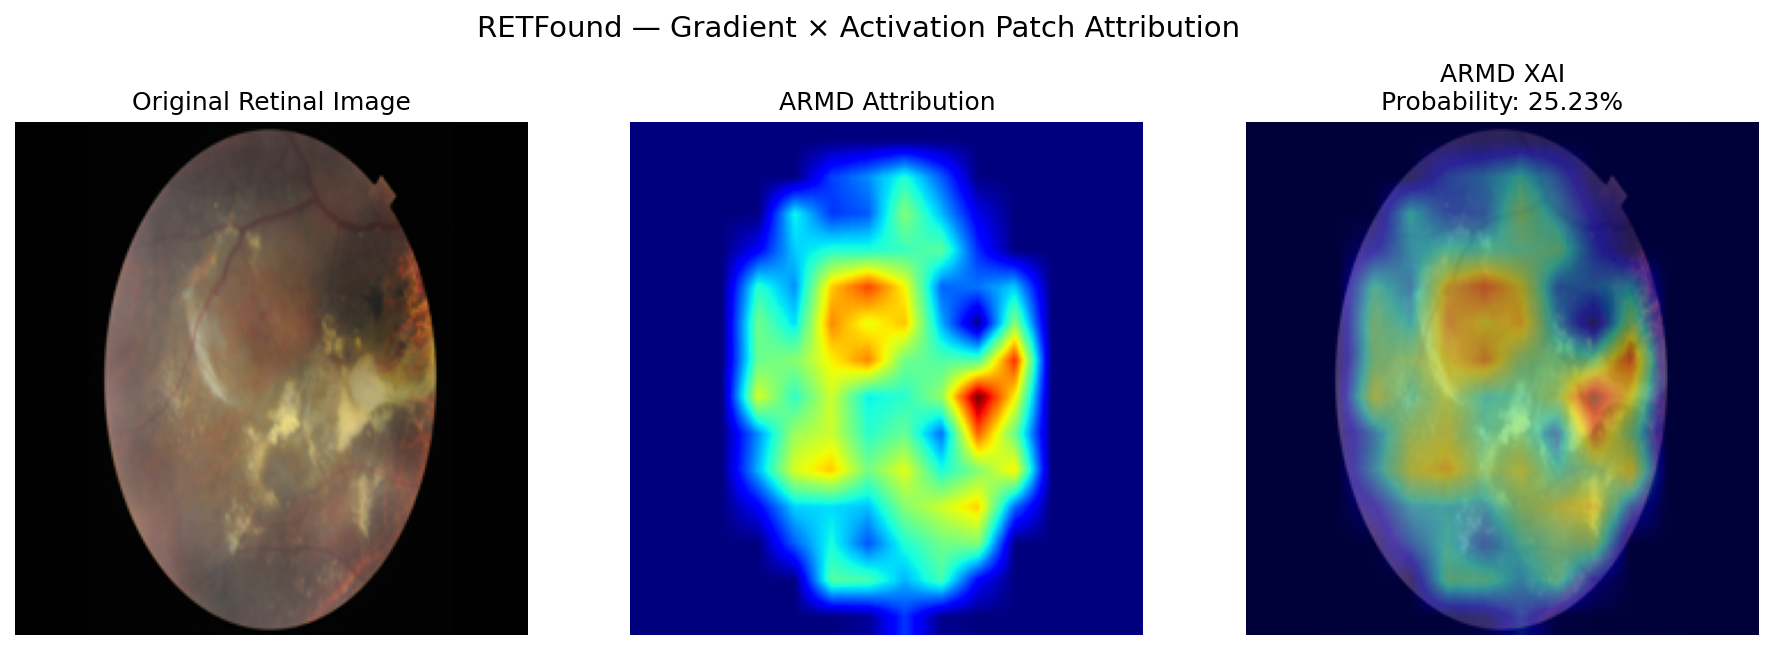


Case 2 — Multi-Label Prediction: TSLN + ARMD

Testing_38_TSLN_XAI.png


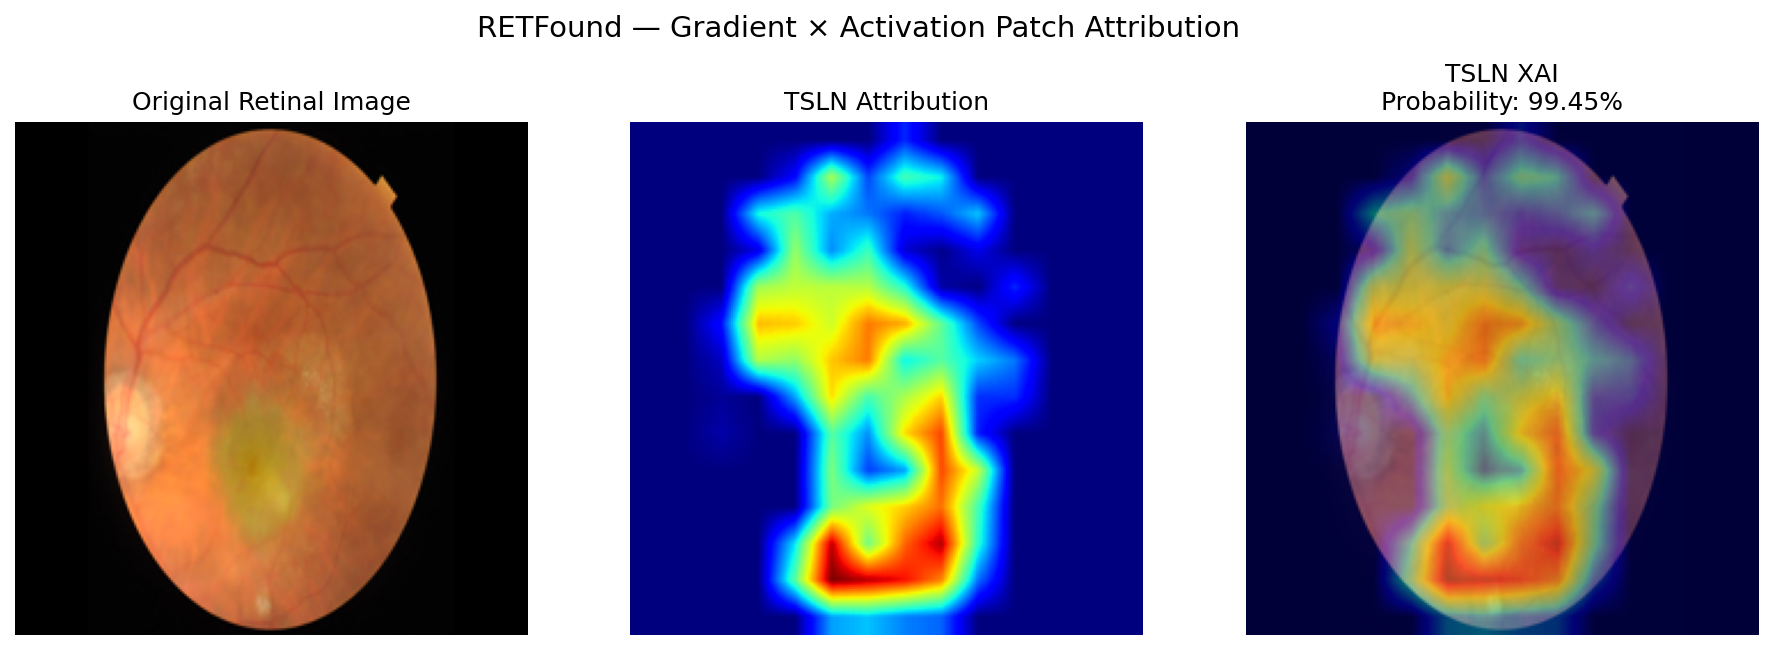


Testing_38_ARMD_XAI.png


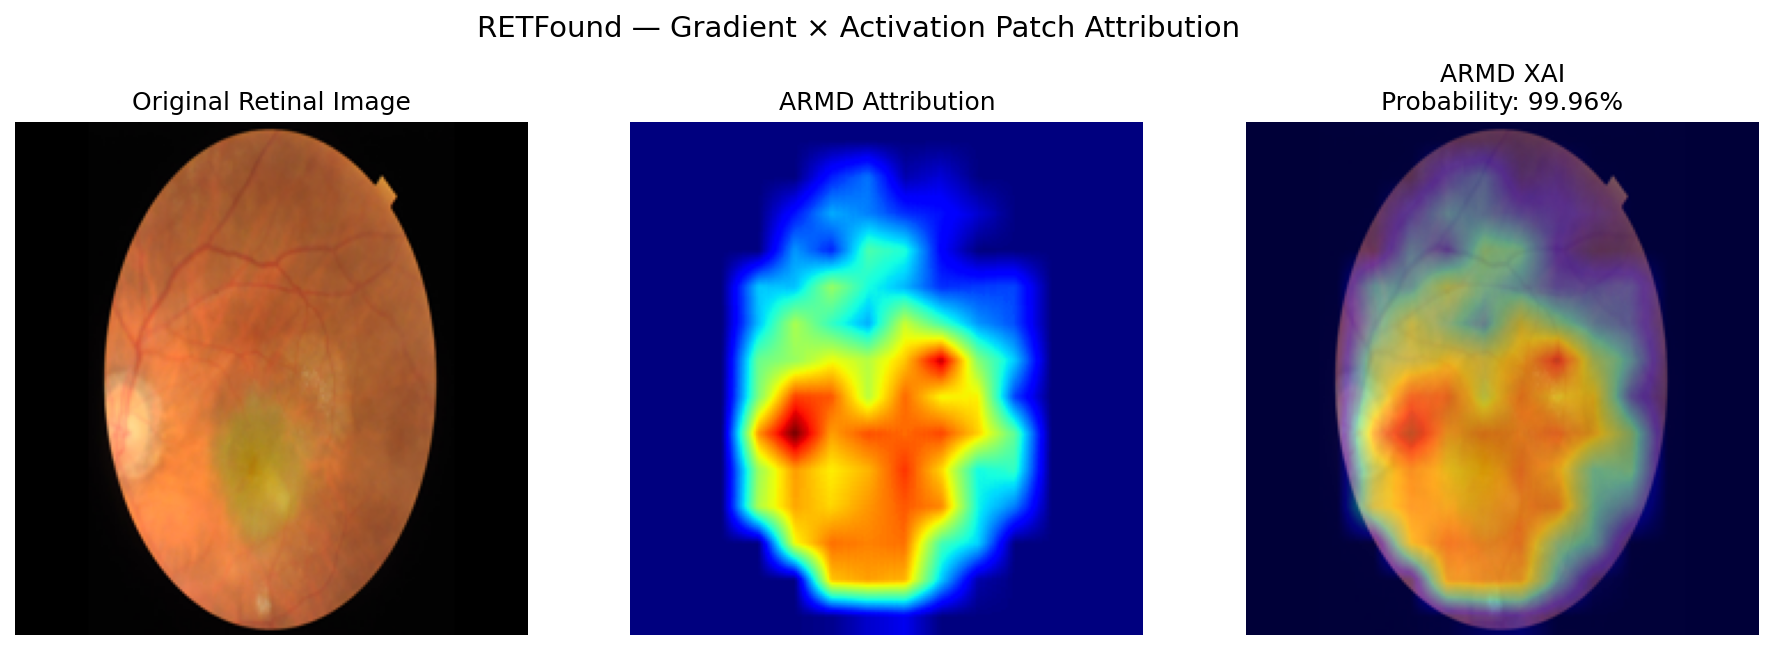


Case 3 — Normal Prediction

Validation_29_Is_Normal_XAI.png


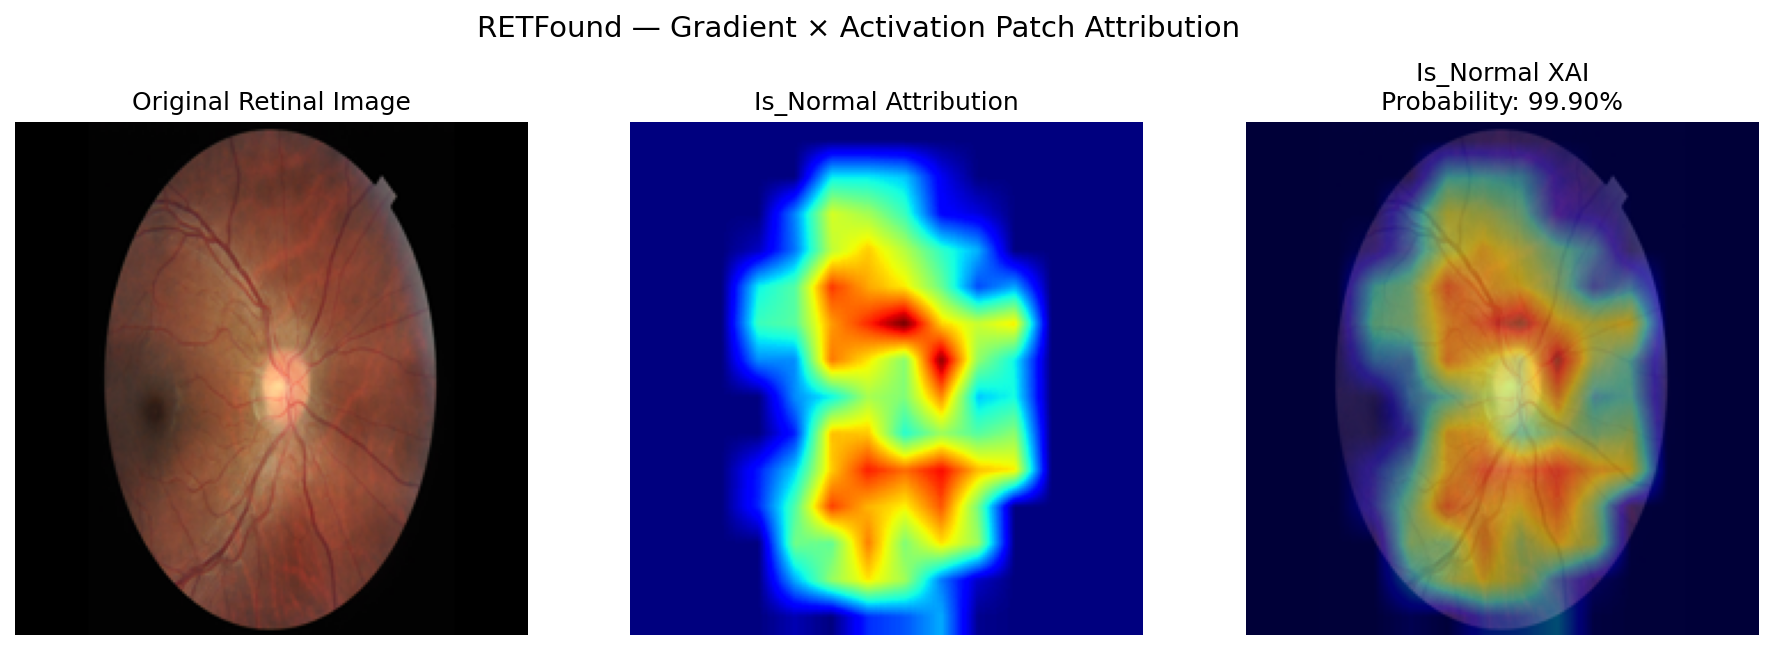


Case 4 — Three-Label Prediction: ODC + TSLN + ODP

Validation_59_ODC_XAI.png


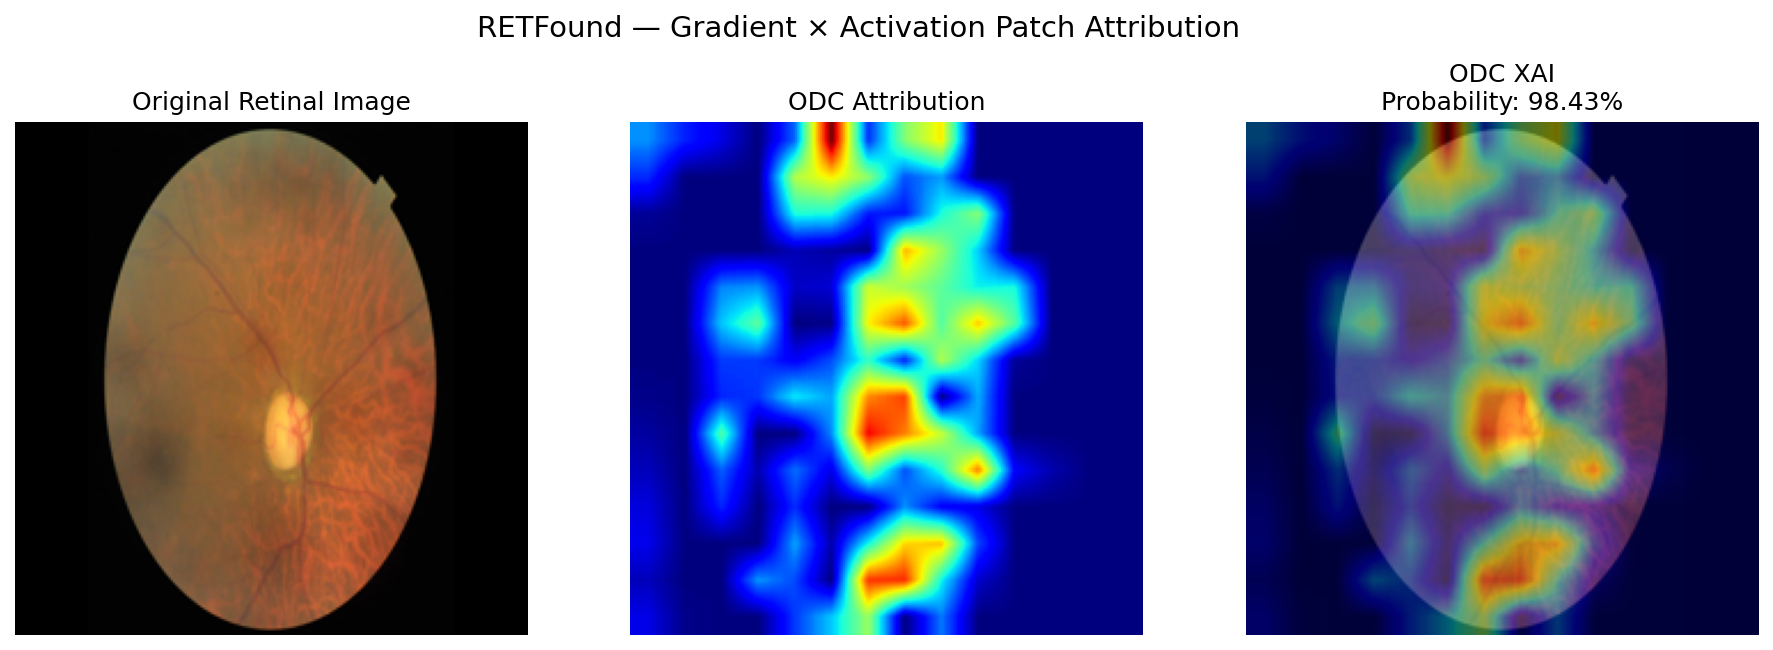


Validation_59_TSLN_XAI.png


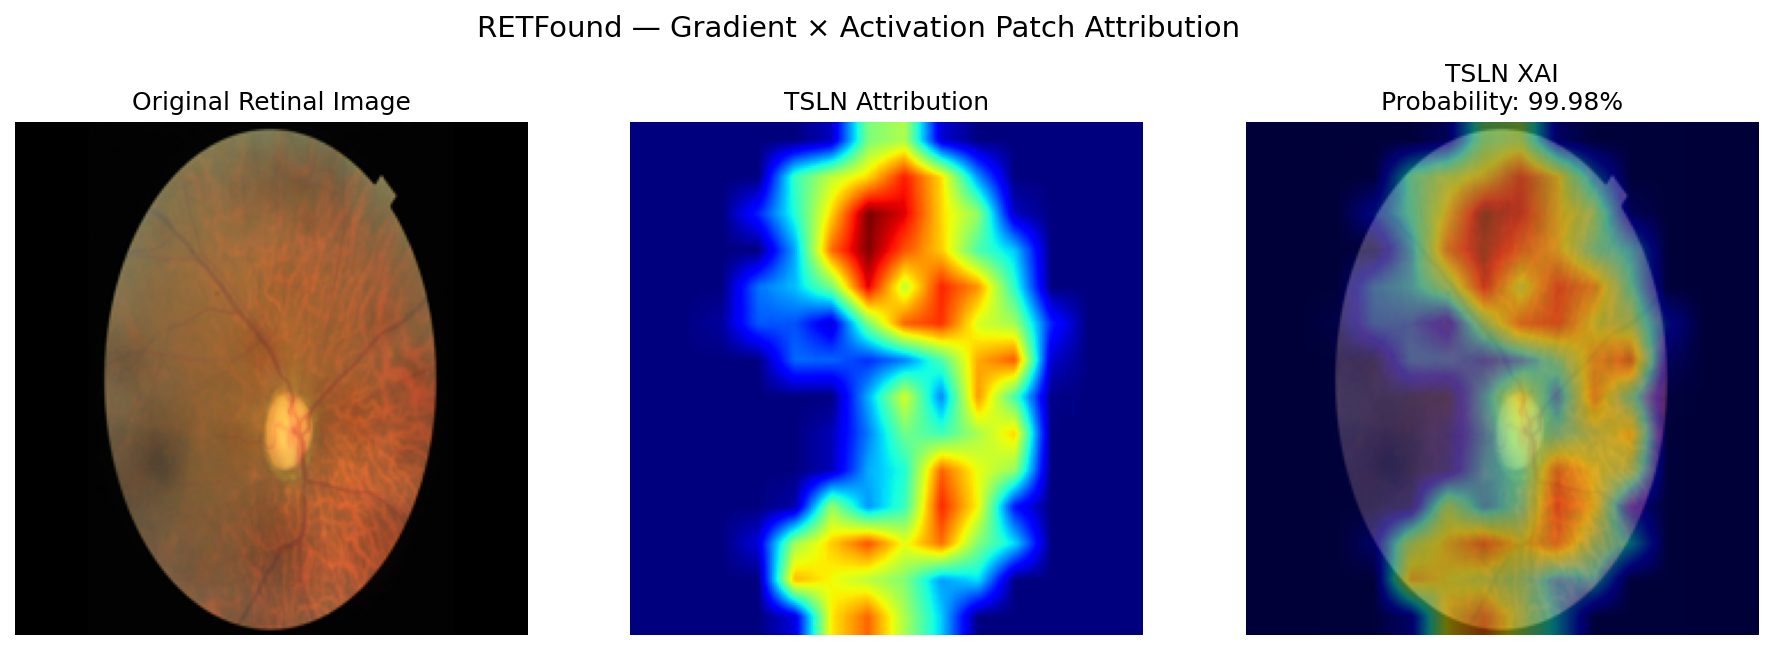


Validation_59_ODP_XAI.png


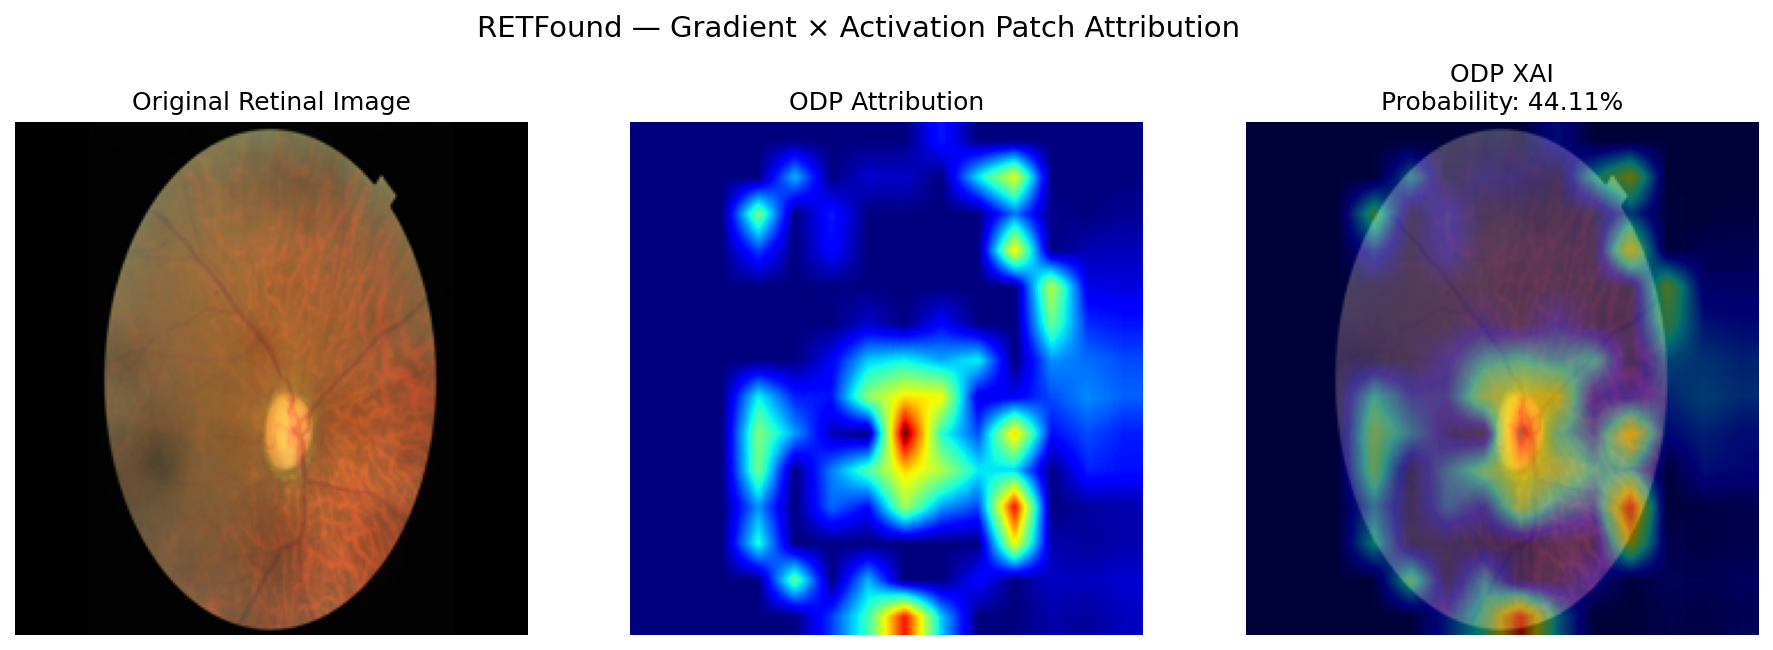


ALL DEMONSTRATIONS DISPLAYED


In [98]:
# ============================================================
# DISPLAY XAI DEMONSTRATIONS DIRECTLY IN KAGGLE NOTEBOOK
# ============================================================

import os
from IPython.display import display, Image as IPImage, HTML

DEMO_DIR = "/kaggle/working/XAI_Demonstrations"

demo_cases = [
    (
        "Case 1 — Single-Label Prediction: ARMD",
        "01_Single_Label_ARMD",
        ["Testing_46_ARMD_XAI.png"]
    ),
    (
        "Case 2 — Multi-Label Prediction: TSLN + ARMD",
        "02_Multi_Label_TSLN_ARMD",
        [
            "Testing_38_TSLN_XAI.png",
            "Testing_38_ARMD_XAI.png"
        ]
    ),
    (
        "Case 3 — Normal Prediction",
        "03_Normal",
        ["Validation_29_Is_Normal_XAI.png"]
    ),
    (
        "Case 4 — Three-Label Prediction: ODC + TSLN + ODP",
        "04_Three_Label_ODC_TSLN_ODP",
        [
            "Validation_59_ODC_XAI.png",
            "Validation_59_TSLN_XAI.png",
            "Validation_59_ODP_XAI.png"
        ]
    )
]

print("=" * 80)
print("XAI DEMONSTRATIONS")
print("=" * 80)

for title, folder, filenames in demo_cases:

    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)

    folder_path = os.path.join(DEMO_DIR, folder)

    for filename in filenames:

        image_path = os.path.join(folder_path, filename)

        if os.path.exists(image_path):

            print(f"\n{filename}")

            # Directly render PNG inside notebook
            display(
                IPImage(
                    filename=image_path,
                    width=900
                )
            )

        else:
            print(f"❌ File not found: {image_path}")

print("\n" + "=" * 80)
print("ALL DEMONSTRATIONS DISPLAYED")
print("=" * 80)